# Лабораторная работа 2: сверточные сети — Pet Vision Lab

**Цель работы.** Научить компьютер узнавать **37 пород кошек и собак** по фотографии (набор Oxford-IIIT Pet), выделять питомца на снимке по пикселям и объяснять, **куда смотрит сеть**, когда принимает решение.

| Часть | Что делаю | Зачем |
|---|---|---|
| 1 | Свёртку и пулинг пишу сам на NumPy | Понять, что такое «слой Conv» изнутри |
| 2 | Небольшая сверточная сеть с нуля (PyTorch) | Узнать, чего можно достичь без предобучения |
| 3 | Transfer learning: ResNet-18 с весами ImageNet | Увидеть, сколько даёт предобучение |
| 4 | U-Net: сегментация «питомец / фон / граница» | Предсказывать класс **каждого пикселя** |
| 5 | Grad-CAM и анализ ошибок | Понять, на что смотрит сеть и почему ошибается |
| Бонус | Зависимость качества от размера данных | Когда transfer learning нужнее всего |

## 0. Подготовка: данные и общие настройки

В ячейке ниже загрузка данных и общие настройки. Я изменил в ней два места, они подписаны в комментариях:

- `NUM_WORKERS`: в Windows `DataLoader` с несколькими процессами не может передать классы, созданные в ноутбуке, поэтому там я ставлю 0 (на Colab/Linux остаётся 2);
- включаю детерминированный режим cuDNN: при одном зерне числа повторяются от запуска к запуску (работает чуть медленнее);
- в конце печатаю, на каком устройстве идёт обучение.

Зерно `SEED = 42` фиксирую, поэтому результаты повторяются от запуска к запуску.

In [1]:
import os
import random
import numpy as np
import torch
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Dataset

# Fix random seeds for reproducibility
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
torch.backends.cudnn.deterministic = True         # deterministic mode: the same seed gives the same numbers on every run
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
NUM_WORKERS = 0 if os.name == "nt" else 2          # on Windows workers cannot pickle classes defined in the notebook, so 0 workers there
IMG_SIZE = 160
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(0.2, 0.2, 0.2),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# ---------- 1. Classification data (Parts 2, 3, 5) ----------
full_trainval = torchvision.datasets.OxfordIIITPet(
    root="./data", split="trainval", target_types="category", download=True)
test_ds = torchvision.datasets.OxfordIIITPet(
    root="./data", split="test", target_types="category", transform=eval_tf, download=True)
CLASSES = full_trainval.classes          # 37 breed names

class TransformSubset(Dataset):
    """Subset with its own transform (train gets augmentation, val does not)."""
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, indices, transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, y = self.base[self.indices[i]]
        return self.transform(img), y

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(full_trainval), generator=g).tolist()
n_val = int(0.2 * len(full_trainval))
val_idx, train_idx = perm[:n_val], perm[n_val:]
train_ds = TransformSubset(full_trainval, train_idx, train_tf)
val_ds   = TransformSubset(full_trainval, val_idx, eval_tf)

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# ---------- 2. Segmentation data (Part 4) ----------
SEG_SIZE = 128
seg_img_tf = T.Compose([
    T.Resize((SEG_SIZE, SEG_SIZE)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
def trimap_to_mask(m):
    # trimap {1: pet, 2: background, 3: border} -> class ids {0, 1, 2}
    return m.squeeze(0).long() - 1
seg_mask_tf = T.Compose([
    T.Resize((SEG_SIZE, SEG_SIZE), interpolation=T.InterpolationMode.NEAREST),
    T.PILToTensor(),
    T.Lambda(trimap_to_mask),
])
seg_trainval = torchvision.datasets.OxfordIIITPet(
    root="./data", split="trainval", target_types="segmentation",
    transform=seg_img_tf, target_transform=seg_mask_tf, download=True)
seg_test = torchvision.datasets.OxfordIIITPet(
    root="./data", split="test", target_types="segmentation",
    transform=seg_img_tf, target_transform=seg_mask_tf, download=True)
seg_train_loader = DataLoader(seg_trainval, batch_size=32, shuffle=True,  num_workers=NUM_WORKERS)
seg_test_loader  = DataLoader(seg_test,     batch_size=32, shuffle=False, num_workers=NUM_WORKERS)

print(f"Train: {len(train_ds)}, Val: {len(val_ds)}, Test: {len(test_ds)}, Classes: {len(CLASSES)}")
x, m = seg_trainval[0]
print("Seg sample:", x.shape, m.shape, m.unique())   # expect mask values tensor([0, 1, 2])
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
Train: 2944, Val: 736, Test: 3669, Classes: 37
Seg sample: torch.Size([3, 128, 128]) torch.Size([128, 128]) tensor([0, 1, 2])
GPU: NVIDIA GeForce RTX 3070 Laptop GPU


In [2]:
import time
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (12, 4.5)
BRAND, LIGHT, INK = "#A30026", "#E9506E", "#2B2B2B"

### 0.1 Смотрим на данные, прежде чем что-то делать

Пять вопросов, на которые нужно ответить **до** обучения (ответы нужны дальше, поэтому считаем их цифрами):

1. Сколько фотографий на породу? (честна ли метрика accuracy и каков уровень «случайного угадывания»)
2. Какие породы кошачьи, какие собачьи? (пригодится в анализе ошибок; в датасете это явно не записано, поэтому выведем из имён файлов и **проверим** по описанию «12 кошек + 25 собак»)
3. Фотографии одного размера? (зачем вообще `Resize`)
4. Какую долю кадра занимает питомец? (пригодится для анализа ошибок и для сегментации)
5. Насколько классы маски сбалансированы? (пригодится в части 4)

In [3]:
labels_trainval = np.array(full_trainval._labels)            # breed id of every trainval image
labels_test = np.array(test_ds._labels)
labels_train, labels_val = labels_trainval[train_idx], labels_trainval[val_idx]

per_class_train = np.bincount(labels_train, minlength=len(CLASSES))
per_class_val = np.bincount(labels_val, minlength=len(CLASSES))
per_class_test = np.bincount(labels_test, minlength=len(CLASSES))
chance_level = 1 / len(CLASSES)

# cat or dog: in this dataset breeds of cats start with an upper-case letter in the file name
file_names = [p.name for p in full_trainval._images]
class_is_cat = np.zeros(len(CLASSES), dtype=bool)
for name, lab in zip(file_names, labels_trainval):
    class_is_cat[lab] = name[0].isupper()
n_cat_breeds, n_dog_breeds = int(class_is_cat.sum()), int((~class_is_cat).sum())

# image sizes on disk (reading the header only, no decoding) for 300 random trainval images
from PIL import Image
rng0 = np.random.RandomState(SEED)
sizes = np.array([Image.open(full_trainval._images[i]).size for i in rng0.choice(len(full_trainval), 300, replace=False)])

# share of pet / background / border pixels in 300 random masks (trimap values 1, 2, 3)
mask_counts = np.zeros(3)
for i in rng0.choice(len(seg_trainval), 300, replace=False):
    trimap = np.array(Image.open(seg_trainval._segs[i]))
    mask_counts += np.bincount(trimap.ravel(), minlength=4)[1:4]
mask_share = mask_counts / mask_counts.sum()

images: train 2944 | val 736 | test 3669
images per breed in train: min 68, max 91, mean 79.6
images per breed in val  : min 9, max 29
images per breed in test : min 88, max 100
random guess accuracy    : 2.7%

breeds: 12 cat + 25 dog = 37  (the description of the dataset says 12 + 25)

image width : median 500, min 133, max 1152
image height: median 375, min 112, max 1734

mask pixels: pet 30.3% | background 58.2% | border 11.5%


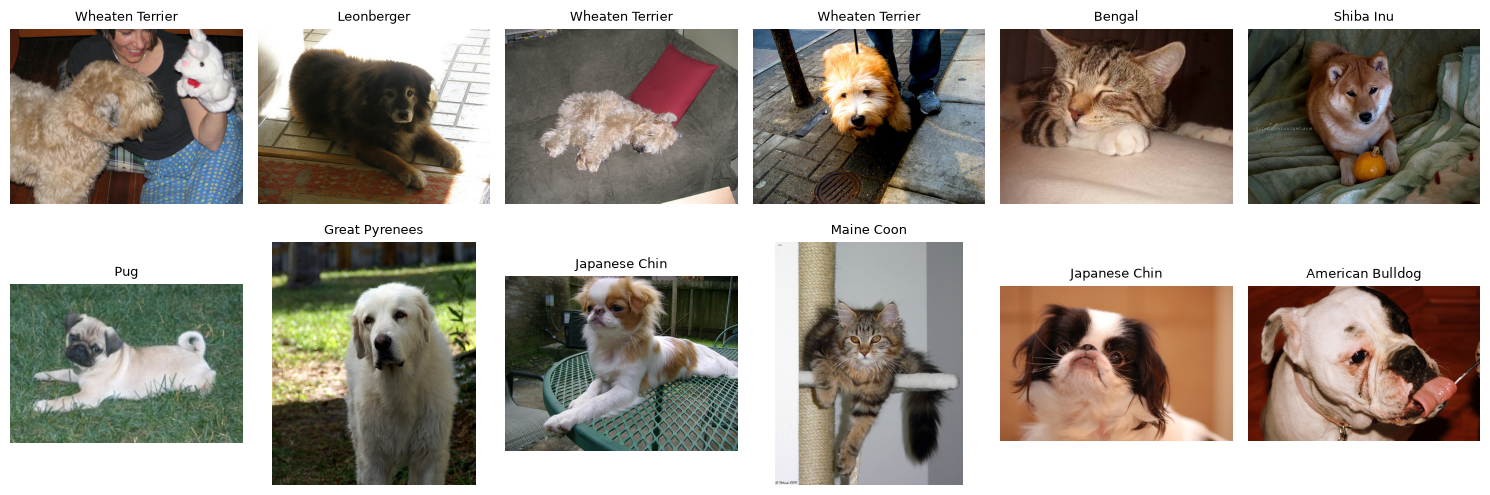

In [4]:
print("images: train %d | val %d | test %d" % (len(train_idx), len(val_idx), len(labels_test)))
print("images per breed in train: min %d, max %d, mean %.1f" % (per_class_train.min(), per_class_train.max(), per_class_train.mean()))
print("images per breed in val  : min %d, max %d" % (per_class_val.min(), per_class_val.max()))
print("images per breed in test : min %d, max %d" % (per_class_test.min(), per_class_test.max()))
print("random guess accuracy    : %.1f%%" % (100 * chance_level))
print("\nbreeds: %d cat + %d dog = %d  (the description of the dataset says 12 + 25)" % (n_cat_breeds, n_dog_breeds, len(CLASSES)))
print("\nimage width : median %d, min %d, max %d" % (np.median(sizes[:, 0]), sizes[:, 0].min(), sizes[:, 0].max()))
print("image height: median %d, min %d, max %d" % (np.median(sizes[:, 1]), sizes[:, 1].min(), sizes[:, 1].max()))
print("\nmask pixels: pet %.1f%% | background %.1f%% | border %.1f%%" % tuple(100 * mask_share))

assert n_cat_breeds == 12 and n_dog_breeds == 25            # the file-name rule reproduces the official split
assert per_class_train.sum() == len(train_idx)

fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
show_ids = np.random.RandomState(1).choice(len(full_trainval), 12, replace=False)
for ax, i in zip(axes.ravel(), show_ids):
    img, y = full_trainval[i]
    ax.imshow(img); ax.set_title(CLASSES[y], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**Вывод по данным** (по цифрам выше):

- В каждой породе в тренировочной части примерно одинаково фотографий (от 68 до 91, в среднем 79,6), поэтому классы **сбалансированы**, и accuracy — честная метрика. Случайный выбор из 37 пород даёт всего **2,7 %**: всё, что выше, — заслуга обучения.
- Правило «кошки — с заглавной буквы» дало ровно **12 + 25** пород, как в описании датасета, поэтому его можно использовать дальше (это проверка, а не догадка).
- Фотографии разного размера и формата, поэтому все приводим к одному (160×160, `Resize`), иначе их нельзя собрать в батч.
- Питомец занимает заметную, но не всю площадь кадра (маска: 30,3 % пикселей — питомец, 58,2 % — фон, 11,5 % — граница). Классы маски **не равны по размеру**; это учтём, читая IoU в части 4.

---
# Часть 1. Свёртка с нуля на NumPy

> В этой части внутри моих функций только NumPy (без `torch`, `scipy.signal`, `cv2`). PyTorch нужен **только в тестах**, чтобы сверить результат. Порядок: теория и формулы, функции, тесты, демо с фильтрами Собеля.

## 1.0 Теория

**Свёртка (convolution)** — это «окно-фильтр», которое скользит по картинке. В каждой позиции фильтр:

1. накладывается на кусок картинки такого же размера (f×f пикселей на всех каналах);
2. каждое число куска умножается на соответствующее число фильтра;
3. всё складывается в **одно число** и к нему прибавляется смещение `b`.

Один фильтр даёт один **канал** результата («карту признаков»). Если фильтров `n_C`, получается `n_C` каналов. Какие признаки ищет фильтр (края, углы, текстуры), сеть **учит сама**: числа фильтра — это её веса.

**Формы массивов** (обозначения Andrew Ng):

| Что | Форма | Расшифровка |
|---|---|---|
| вход `A_prev` | `(m, n_H_prev, n_W_prev, n_C_prev)` | m картинок, высота, ширина, каналы |
| фильтры `W` | `(f, f, n_C_prev, n_C)` | n_C фильтров размера f×f, каждый видит все входные каналы |
| смещения `b` | `(1, 1, 1, n_C)` | по одному на фильтр |
| выход `Z` | `(m, n_H, n_W, n_C)` | |

**Размер выхода:**

```
n_H = floor( (n_H_prev + 2·pad − f) / stride ) + 1        (так же для n_W)
```

- **padding** — нулевая рамка вокруг картинки. Без неё картинка с каждой свёрткой уменьшается, а пиксели по краям участвуют реже, чем центральные. При `f = 3`, `stride = 1`, `pad = 1` размер **сохраняется**.
- **stride** — шаг окна. При `stride = 2` выход вдвое меньше.

**Пулинг (pooling)** — окно f×f, шаг s, из окна берётся **максимум** (max) или **среднее** (average); каналы не смешиваются, параметров нет. Размер выхода: `floor((n_H_prev − f)/s) + 1`.

In [5]:
# Check the output-size formula on the sizes that this lab really uses (pure arithmetic, no convolution code).
def out_size(n, f, stride, pad):
    return (n + 2 * pad - f) // stride + 1

cases = [("тест conv_forward", 7, 3, 2, 1), ("тест pool_forward", 6, 2, 2, 0),
         ("Conv3x3 pad1 в SimpleCNN", 160, 3, 1, 1), ("MaxPool2 в SimpleCNN", 160, 2, 2, 0)]
size_table = [(name, n, f, s, p, out_size(n, f, s, p)) for name, n, f, s, p in cases]

In [6]:
print("%-26s %5s %3s %6s %4s %8s" % ("где", "n", "f", "stride", "pad", "выход"))
for row in size_table:
    print("%-26s %5d %3d %6d %4d %8d" % row)
assert size_table[0][-1] == 4 and size_table[1][-1] == 3     # the shapes that the tests below expect
assert size_table[2][-1] == 160 and size_table[3][-1] == 80

где                            n   f stride  pad    выход
тест conv_forward              7   3      2    1        4
тест pool_forward              6   2      2    0        3
Conv3x3 pad1 в SimpleCNN     160   3      1    1      160
MaxPool2 в SimpleCNN         160   2      2    0       80


Формула даёт ровно те размеры, которые требуют тесты ниже (4 и 3), и показывает, что `Conv 3×3, pad 1` сохраняет размер, а `MaxPool 2` делит его пополам: это пригодится в части 2.

## 1.1 Нулевое дополнение — `zero_pad`

**Как делаю.** У массива `X` формы `(m, n_H, n_W, n_C)` дополнять нужно только высоту (ось 1) и ширину (ось 2), а число картинок (ось 0) и каналы (ось 3) трогать нельзя. Для `np.pad` это значит: для осей 0 и 3 пишу `(0, 0)`, для осей 1 и 2 — `(pad, pad)`, режим «константа», значение 0.

**Как проверяю себя.** Форма результата `(m, n_H + 2·pad, n_W + 2·pad, n_C)`, рамка нулевая, середина равна исходному массиву (это и проверяет `test_zero_pad`).

In [7]:
def zero_pad(X, pad):
    """Pad with zeros only the height and width axes of X, shape (m, n_H, n_W, n_C).

    Returns an array of shape (m, n_H + 2*pad, n_W + 2*pad, n_C).
    """
    # ось 0 (картинки) и ось 3 (каналы) не трогаем, высоту и ширину дополняем нулями
    X_pad = np.pad(X, ((0, 0), (pad, pad), (pad, pad), (0, 0)), mode="constant", constant_values=0)
    return X_pad

## 1.2 Свёртка — `conv_single_step` и `conv_forward`

**`conv_single_step(a_slice, W, b)`** — одна позиция окна. `a_slice` и `W` имеют форму `(f, f, n_C_prev)`; `b` — `(1, 1, 1)`. Умножаю поэлементно, суммирую всё, прибавляю смещение. Возвращает **число**. Тонкость: `b` приходит как массив формы `(1,1,1)`, а результат должен быть обычным числом, поэтому беру `b.item()`.

**Как устроен `conv_forward(A_prev, W, b, hparams)`**, `hparams = {"stride": s, "pad": p}`:

1. Достаю из форм `A_prev` и `W` числа `m, n_H_prev, n_W_prev, n_C_prev, f, n_C`, а из `hparams` — `stride` и `pad`.
2. Считаю `n_H` и `n_W` по формуле из 1.0 (целое деление `//`).
3. Создаю выход `Z` из нулей формы `(m, n_H, n_W, n_C)`.
4. Один раз до циклов дополняю вход нулями (`zero_pad`).
5. Четыре вложенных цикла: картинка `i`, позиция окна по высоте `h`, по ширине `w`, фильтр `c`.
6. Верхний левый угол среза в **дополненной** картинке — `(h·stride, w·stride)`, размер среза `f×f`, берутся **все** входные каналы.
7. Для фильтра `c` беру `W[..., c]` и `b[..., c]`, вызываю `conv_single_step`, записываю в `Z[i, h, w, c]`.
8. Проверяю форму `Z` через `assert` и возвращаю `Z` и `cache = (A_prev, W, b, hparams)`.

**Ошибки, которых я старался избежать:** перепутать порядок осей `W`; резать срез из недополненной картинки; забыть умножить индекс окна на `stride`; взять смещение не того фильтра.

In [8]:
def conv_single_step(a_slice, W, b):
    """One filter applied to one slice. a_slice, W: (f, f, n_C_prev); b: (1, 1, 1). Returns a scalar."""
    s = a_slice * W                  # поэлементное произведение
    Z = np.sum(s)                    # сумма всех f*f*n_C_prev произведений
    return Z + b.item()              # b.item() - обычное число вместо массива (1,1,1)


def conv_forward(A_prev, W, b, hparams):
    """A_prev: (m, n_H_prev, n_W_prev, n_C_prev); W: (f, f, n_C_prev, n_C); b: (1, 1, 1, n_C);
    hparams = {"stride": s, "pad": p}. Returns (Z, cache), Z: (m, n_H, n_W, n_C)."""
    m, n_H_prev, n_W_prev, n_C_prev = A_prev.shape
    f, f, n_C_prev, n_C = W.shape
    stride, pad = hparams["stride"], hparams["pad"]

    n_H = (n_H_prev + 2 * pad - f) // stride + 1
    n_W = (n_W_prev + 2 * pad - f) // stride + 1
    Z = np.zeros((m, n_H, n_W, n_C))

    A_prev_pad = zero_pad(A_prev, pad)       # padding делаем один раз, до циклов

    for i in range(m):                       # по картинкам
        for h in range(n_H):                 # по позиции окна (высота)
            for w in range(n_W):             # по позиции окна (ширина)
                top, left = h * stride, w * stride
                a_slice = A_prev_pad[i, top:top + f, left:left + f, :]     # срез по всем каналам
                for c in range(n_C):         # по фильтрам
                    Z[i, h, w, c] = conv_single_step(a_slice, W[:, :, :, c], b[:, :, :, c])

    assert Z.shape == (m, n_H, n_W, n_C)
    cache = (A_prev, W, b, hparams)
    return Z, cache

## 1.3 Пулинг — `pool_forward`

**Как делаю** `pool_forward(A_prev, hparams, mode)`, `hparams = {"f": f, "stride": s}`:

1. Формы: `m, n_H_prev, n_W_prev, n_C` из `A_prev`; `f` и `stride` из `hparams`.
2. Размер выхода: `n_H = (n_H_prev − f)//stride + 1` (дополнения нулями нет), так же `n_W`; каналов столько же, сколько на входе.
3. Циклы по картинке, позиции окна и **каналу**: каждый канал пулится отдельно, каналы не смешиваются.
4. Срез окна — как в свёртке (угол `h·stride`, `w·stride`, размер `f`), но только один канал.
5. `mode == "max"` — максимум по окну, `mode == "average"` — среднее; любой другой режим — `ValueError`.
6. Возвращаю `(A, cache)`.

In [9]:
def pool_forward(A_prev, hparams, mode="max"):
    """A_prev: (m, n_H_prev, n_W_prev, n_C); hparams = {"f": f, "stride": s}; mode: "max" or "average".
    Returns (A, cache), A: (m, n_H, n_W, n_C)."""
    m, n_H_prev, n_W_prev, n_C = A_prev.shape
    f, stride = hparams["f"], hparams["stride"]

    n_H = (n_H_prev - f) // stride + 1
    n_W = (n_W_prev - f) // stride + 1
    A = np.zeros((m, n_H, n_W, n_C))

    for i in range(m):
        for h in range(n_H):
            for w in range(n_W):
                top, left = h * stride, w * stride
                for c in range(n_C):         # каждый канал пулим отдельно
                    window = A_prev[i, top:top + f, left:left + f, c]
                    if mode == "max":
                        A[i, h, w, c] = np.max(window)
                    elif mode == "average":
                        A[i, h, w, c] = np.mean(window)
                    else:
                        raise ValueError("mode must be 'max' or 'average'")

    assert A.shape == (m, n_H, n_W, n_C)
    cache = (A_prev, hparams)
    return A, cache

## Тесты части 1

Тесты сравнивают мои функции с PyTorch на случайных данных. Все три функции проходят свои тесты, при любой ошибке в `assert` ячейка падает.

In [10]:
import torch.nn.functional as F

def test_zero_pad(zero_pad):
    x = np.random.randn(4, 3, 3, 2)
    x_pad = zero_pad(x, 2)
    assert x_pad.shape == (4, 7, 7, 2)
    assert np.all(x_pad[:, :2, :, :] == 0)
    assert np.allclose(x_pad[:, 2:5, 2:5, :], x)

def test_conv_forward(conv_forward):
    rng = np.random.default_rng(1)
    A = rng.standard_normal((2, 7, 7, 3))
    W = rng.standard_normal((3, 3, 3, 4))
    b = rng.standard_normal((1, 1, 1, 4))
    Z, _ = conv_forward(A, W, b, {"stride": 2, "pad": 1})
    ref = F.conv2d(torch.tensor(A).permute(0, 3, 1, 2),
                   torch.tensor(W).permute(3, 2, 0, 1),
                   torch.tensor(b).flatten(), stride=2, padding=1).permute(0, 2, 3, 1).numpy()
    assert Z.shape == (2, 4, 4, 4)
    assert np.allclose(Z, ref, atol=1e-6)

def test_pool_forward(pool_forward):
    rng = np.random.default_rng(2)
    A = rng.standard_normal((2, 6, 6, 3))
    P, _ = pool_forward(A, {"f": 2, "stride": 2}, mode="max")
    ref = F.max_pool2d(torch.tensor(A).permute(0, 3, 1, 2), 2, 2).permute(0, 2, 3, 1).numpy()
    assert P.shape == (2, 3, 3, 3)
    assert np.allclose(P, ref)
    P_avg, _ = pool_forward(A, {"f": 2, "stride": 2}, mode="average")
    ref_avg = F.avg_pool2d(torch.tensor(A).permute(0, 3, 1, 2), 2, 2).permute(0, 2, 3, 1).numpy()
    assert np.allclose(P_avg, ref_avg)

test_zero_pad(zero_pad); test_conv_forward(conv_forward); test_pool_forward(pool_forward)
print("All Part 1 tests passed!")

All Part 1 tests passed!


## 1.4 Детектор краёв: фильтры Собеля

**Идея.** Фильтр — это просто маленькая таблица чисел. Если подобрать числа определённым образом, фильтр начинает реагировать на **границы**. Фильтры Собеля 3×3:

```
вертикальный (Sobel X)     горизонтальный (Sobel Y)
  -1  0  +1                   -1  -2  -1
  -2  0  +2                    0   0   0
  -1  0  +1                   +1  +2  +1
```

Первый вычитает левый столбец из правого: он «видит» изменение яркости **слева направо**, то есть **вертикальные** границы. Второй вычитает верхнюю строку из нижней и «видит» **горизонтальные** границы. На ровном участке сумма чисел фильтра нулевая, поэтому отклик нулевой.

Чтобы объяснение не осталось словами, сначала **измерим** отклик каждого фильтра на двух синтетических картинках: на одной вертикальная граница (слева тёмное, справа светлое), на другой горизонтальная.

In [11]:
SOBEL_X = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float).reshape(3, 3, 1, 1)   # vertical edges
SOBEL_Y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=float).reshape(3, 3, 1, 1)     # horizontal edges
ZERO_BIAS = np.zeros((1, 1, 1, 1))
EDGE_PARAMS = {"stride": 1, "pad": 1}

img_vertical = np.zeros((1, 16, 16, 1)); img_vertical[:, :, 8:, :] = 1.0        # left dark, right bright
img_horizontal = np.zeros((1, 16, 16, 1)); img_horizontal[:, 8:, :, :] = 1.0    # top dark, bottom bright


def mean_response(image, kernel):
    Z, _ = conv_forward(image, kernel, ZERO_BIAS, EDGE_PARAMS)
    return np.abs(Z[0, 2:-2, 2:-2, 0]).mean()      # skip the image border where zero padding makes an artificial edge


response = pd.DataFrame(
    {"vertical-edge image": [mean_response(img_vertical, SOBEL_X), mean_response(img_vertical, SOBEL_Y)],
     "horizontal-edge image": [mean_response(img_horizontal, SOBEL_X), mean_response(img_horizontal, SOBEL_Y)]},
    index=["Sobel X (vertical edges)", "Sobel Y (horizontal edges)"]).round(3)

In [12]:
print("mean |response| of each filter (borders of the image excluded):")
print(response)
# each filter must respond to 'its' edge and stay quiet on the other one
assert response.iloc[0, 0] > 5 * response.iloc[0, 1] + 1e-9
assert response.iloc[1, 1] > 5 * response.iloc[1, 0] + 1e-9

mean |response| of each filter (borders of the image excluded):
                            vertical-edge image  horizontal-edge image
Sobel X (vertical edges)                  0.667                  0.000
Sobel Y (horizontal edges)                0.000                  0.667


Теперь тот же фильтр на настоящей фотографии: перевожу снимок в серый цвет, применяю **мой** `conv_forward` с обоими фильтрами и показываю три картинки рядом.

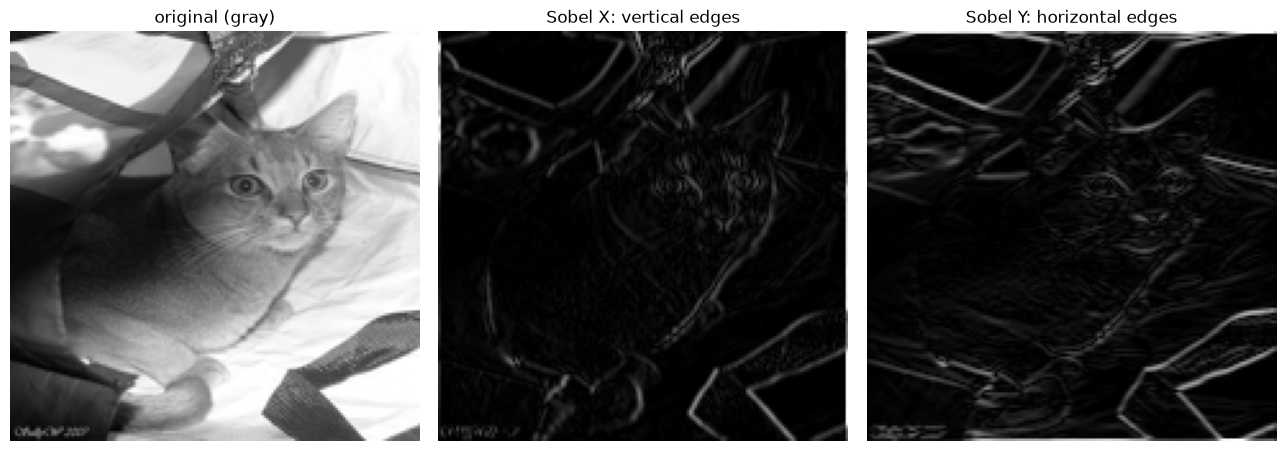

In [13]:
from PIL import Image as PILImage
pet_image = full_trainval[0][0].convert("L").resize((160, 160))
gray = np.asarray(pet_image, dtype=float).reshape(1, 160, 160, 1) / 255.0
map_x, _ = conv_forward(gray, SOBEL_X, ZERO_BIAS, EDGE_PARAMS)
map_y, _ = conv_forward(gray, SOBEL_Y, ZERO_BIAS, EDGE_PARAMS)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
axes[0].imshow(gray[0, :, :, 0], cmap="gray"); axes[0].set_title("original (gray)")
axes[1].imshow(np.abs(map_x[0, :, :, 0]), cmap="gray"); axes[1].set_title("Sobel X: vertical edges")
axes[2].imshow(np.abs(map_y[0, :, :, 0]), cmap="gray"); axes[2].set_title("Sobel Y: horizontal edges")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### Вывод 1.4

- **Sobel X** (`−1 0 +1`) вычитает левые пиксели из правых, поэтому отвечает на **вертикальные** границы. Измерение на синтетических картинках это подтверждает: средний отклик Sobel X на картинке с вертикальной границей **0,667**, на картинке с горизонтальной **0,000**; у Sobel Y всё наоборот (проверено `assert`).
- **Sobel Y** вычитает верхнюю строку из нижней и отвечает на **горизонтальные** границы. На фотографии кошки Sobel X подсвечивает вертикальные линии (боковые линии лямок сумки, контур щеки и ушей), а Sobel Y — горизонтальные (нижние края сумки, линия лап).
- **Что это значит для сети.** Первый слой обученной сверточной сети делает то же самое, но числа фильтров не задаю я: сеть подбирает их сама. В части 3 видно, что у ResNet-18 с весами ImageNet первые фильтры действительно гладкие детекторы краёв и цвета.

---
# Часть 2. Базовая сверточная сеть с нуля в PyTorch

## 2.0 Теория

Сверточная сеть строится из повторяющихся блоков. В нашем блоке четыре шага:

| Шаг | Что делает | Параметров |
|---|---|---|
| `Conv2d(3×3, padding=1)` | ищет 3×3-узоры; размер картинки сохраняется | `(3·3·C_in + 1)·C_out` |
| `BatchNorm2d` | выравнивает среднее и разброс по каждому каналу: обучение стабильнее | `2·C` (γ и β) |
| `ReLU` | отрезает отрицательные значения (нелинейность) | 0 |
| `MaxPool2d(2)` | оставляет максимум из 2×2: картинка вдвое меньше, признак «где-то здесь» | 0 |

Четыре таких блока (каналы 32 → 64 → 128 → 256) превращают картинку 160×160×3 в карту 10×10×256, дальше `AdaptiveAvgPool2d(1)` усредняет её до вектора из 256 чисел, `Dropout(0.3)` борется с переобучением, `Linear(256 → 37)` выдаёт баллы 37 пород.

## 2.1 Архитектура и таблица, посчитанная вручную

Таблицу «форма выхода и число параметров каждого слоя» я сначала **считаю по формулам**, а потом сверяю с PyTorch. Порядок: сначала формулы (ниже, без обращения к модели), потом настоящая модель, потом сравнение строка за строкой.

In [14]:
import torch.nn as nn
import torch.nn.functional as F


class SimpleCNN(nn.Module):
    def __init__(self, num_classes=37, p_drop=0.3):
        super().__init__()
        chans = [3, 32, 64, 128, 256]
        blocks = []
        for c_in, c_out in zip(chans[:-1], chans[1:]):
            blocks += [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p_drop), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.head(self.features(x))


# ---- by hand: output shape and parameters of every layer, from the formulas only ----
hand_table = []
side, c_in = IMG_SIZE, 3
for k, c_out in enumerate([32, 64, 128, 256], start=1):
    hand_table.append(("Conv2d %d: 3x3, %d -> %d" % (k, c_in, c_out), (c_out, side, side), (3 * 3 * c_in + 1) * c_out))
    hand_table.append(("BatchNorm2d %d" % k, (c_out, side, side), 2 * c_out))
    hand_table.append(("ReLU %d" % k, (c_out, side, side), 0))
    side //= 2
    hand_table.append(("MaxPool2d %d" % k, (c_out, side, side), 0))
    c_in = c_out
hand_table += [("AdaptiveAvgPool2d(1)", (256, 1, 1), 0), ("Flatten", (256,), 0), ("Dropout(0.3)", (256,), 0),
               ("Linear 256 -> 37", (37,), (256 + 1) * len(CLASSES))]
hand_total = sum(p for _, _, p in hand_table)

# ---- the real model: record the output shape and the parameters of every leaf layer ----
cnn_demo = SimpleCNN().to(device)
real_table = []
def make_hook(module):
    def hook(mod, inp, out):
        real_table.append((tuple(out.shape[1:]), sum(p.numel() for p in mod.parameters(recurse=False))))
    return hook
handles = [m.register_forward_hook(make_hook(m)) for m in cnn_demo.modules() if len(list(m.children())) == 0]
with torch.no_grad():
    cnn_demo.eval()(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=device))
for h in handles:
    h.remove()
real_total = sum(p.numel() for p in cnn_demo.parameters())

arch_table = pd.DataFrame({
    "layer": [r[0] for r in hand_table],
    "output shape (by hand)": [str(r[1]) for r in hand_table],
    "params (by hand)": [r[2] for r in hand_table],
    "output shape (PyTorch)": [str(r[0]) for r in real_table],
    "params (PyTorch)": [r[1] for r in real_table],
})
arch_table["match"] = (arch_table["output shape (by hand)"] == arch_table["output shape (PyTorch)"]) & \
                      (arch_table["params (by hand)"] == arch_table["params (PyTorch)"])

In [15]:
print(arch_table.to_string())
print("\ntotal parameters: by hand %d | sum(p.numel()) %d" % (hand_total, real_total))
assert len(hand_table) == len(real_table)
assert arch_table["match"].all()                      # every row of the hand calculation equals PyTorch
assert hand_total == real_total
del cnn_demo

                        layer output shape (by hand)  params (by hand) output shape (PyTorch)  params (PyTorch)  match
0      Conv2d 1: 3x3, 3 -> 32         (32, 160, 160)               896         (32, 160, 160)               896   True
1               BatchNorm2d 1         (32, 160, 160)                64         (32, 160, 160)                64   True
2                      ReLU 1         (32, 160, 160)                 0         (32, 160, 160)                 0   True
3                 MaxPool2d 1           (32, 80, 80)                 0           (32, 80, 80)                 0   True
4     Conv2d 2: 3x3, 32 -> 64           (64, 80, 80)             18496           (64, 80, 80)             18496   True
5               BatchNorm2d 2           (64, 80, 80)               128           (64, 80, 80)               128   True
6                      ReLU 2           (64, 80, 80)                 0           (64, 80, 80)                 0   True
7                 MaxPool2d 2           (64, 40,

**Вывод 2.1.** Все 20 строк таблицы, посчитанные по формулам, **совпали с PyTorch** (форма и число параметров каждого слоя), а сумма **398 885** равна `sum(p.numel() for p in model.parameters())`. Видно, где живут параметры: больше 70 % (295 168 + 512) — в четвёртой свёртке (128 → 256 каналов), а `BatchNorm`, `ReLU` и пулинг почти ничего не весят. Размер картинки падает 160 → 80 → 40 → 20 → 10, как и предсказывает формула из части 1.

## 2.2 Цикл обучения (будем использовать и в части 3)

`train_one_epoch` — один проход по обучающим данным с обновлением весов, `evaluate` — только измерение (без обновления, без dropout). Параметр `freeze_bn` понадобится в 3.1.

In [16]:
def train_one_epoch(model, loader, optimizer, scheduler=None, freeze_bn=False):
    model.train()
    if freeze_bn:                                   # keep the BatchNorm statistics of the pretrained network
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module.eval()
    total_loss, correct, count = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        count += len(y)
    if scheduler is not None:
        scheduler.step()
    return total_loss / count, correct / count


@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    logits_list, labels_list = [], []
    for x, y in loader:
        logits_list.append(model(x.to(device, non_blocking=True)).float().cpu())
        labels_list.append(y)
    return torch.cat(logits_list), torch.cat(labels_list)


def evaluate(model, loader):
    logits, y = predict_all(model, loader)
    return F.cross_entropy(logits, y).item(), (logits.argmax(1) == y).float().mean().item()


def fit(model, optimizer, epochs, scheduler=None, freeze_bn=False, loader=None, log=True):
    loader = train_loader if loader is None else loader
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}
    for epoch in range(epochs):
        start = time.time()
        tl, ta = train_one_epoch(model, loader, optimizer, scheduler, freeze_bn)
        vl, va = evaluate(model, val_loader)
        for key, value in zip(["train_loss", "train_acc", "val_loss", "val_acc"], [tl, ta, vl, va]):
            hist[key].append(value)
        hist["epoch_time"].append(time.time() - start)
        if log:
            print("epoch %2d | train loss %.3f acc %.3f | val loss %.3f acc %.3f | %.0f s" % (epoch + 1, tl, ta, vl, va, hist["epoch_time"][-1]))
    return hist


def set_seed(seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)

### Проверка 1: цикл обучения вообще способен обучать

Прежде чем тратить время на 15 эпох, проверяем два простых утверждения:

1. **Нет «подсматривания».** До обучения accuracy ≈ случайному угадыванию (1/37 = 2,7 %), а loss ≈ ln 37 = 3,61 (так выглядит «равномерное» предсказание 37 классов).
2. **Модель умеет учиться.** Классический тест: показываем сети **один и тот же** батч из 64 картинок 80 раз. Если цикл и модель в порядке, loss должен упасть почти до нуля (сеть запомнит эти 64 картинки).

In [17]:
set_seed()
sanity_model = SimpleCNN().to(device)
loss_before, acc_before = evaluate(sanity_model, val_loader)

one_x, one_y = next(iter(val_loader))
one_x, one_y = one_x.to(device), one_y.to(device)
sanity_opt = torch.optim.AdamW(sanity_model.parameters(), lr=1e-3)
sanity_losses = []
sanity_model.train()
for step in range(80):
    sanity_opt.zero_grad()
    logits = sanity_model(one_x)
    loss = F.cross_entropy(logits, one_y)
    loss.backward(); sanity_opt.step()
    sanity_losses.append(loss.item())
sanity_model.eval()
with torch.no_grad():
    acc_one_batch = (sanity_model(one_x).argmax(1) == one_y).float().mean().item()

In [18]:
print("before training: val accuracy %.3f (random guess %.3f), val loss %.2f (ln 37 = %.2f)" % (acc_before, chance_level, loss_before, np.log(37)))
print("same 64 images, 80 steps: loss %.2f -> %.3f, accuracy on them %.2f" % (sanity_losses[0], sanity_losses[-1], acc_one_batch))
assert acc_before < 0.15 and abs(loss_before - np.log(37)) < 1.0         # before training = guessing
assert sanity_losses[-1] < 0.1 * sanity_losses[0] and acc_one_batch > 0.9  # can memorise one batch
del sanity_model, sanity_opt

before training: val accuracy 0.023 (random guess 0.027), val loss 3.61 (ln 37 = 3.61)
same 64 images, 80 steps: loss 3.72 -> 0.103, accuracy on them 1.00


**Вывод проверки 1.** До обучения сеть угадывает на уровне случайного выбора, а на одном батче loss падает почти до нуля: значит, модель, оптимизатор и цикл связаны правильно, и дальше результат зависит только от данных и гиперпараметров.

## 2.2 Обучение: 15 эпох, AdamW (lr = 1e-3, weight_decay = 1e-4)

In [19]:
set_seed()
baseline_model = SimpleCNN().to(device)
baseline_opt = torch.optim.AdamW(baseline_model.parameters(), lr=1e-3, weight_decay=1e-4)
baseline_hist = fit(baseline_model, baseline_opt, epochs=15)
baseline_params = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)

epoch  1 | train loss 3.545 acc 0.065 | val loss 3.563 acc 0.052 | 18 s


epoch  2 | train loss 3.395 acc 0.098 | val loss 3.524 acc 0.086 | 18 s


epoch  3 | train loss 3.332 acc 0.097 | val loss 3.404 acc 0.082 | 18 s


epoch  4 | train loss 3.240 acc 0.124 | val loss 3.413 acc 0.082 | 18 s


epoch  5 | train loss 3.177 acc 0.141 | val loss 3.294 acc 0.125 | 18 s


epoch  6 | train loss 3.077 acc 0.161 | val loss 3.233 acc 0.130 | 18 s


... (5 outputs left out)

epoch 12 | train loss 2.699 acc 0.251 | val loss 3.024 acc 0.173 | 18 s


epoch 13 | train loss 2.676 acc 0.262 | val loss 3.061 acc 0.158 | 18 s


epoch 14 | train loss 2.618 acc 0.274 | val loss 2.904 acc 0.183 | 18 s


epoch 15 | train loss 2.551 acc 0.284 | val loss 2.988 acc 0.192 | 18 s


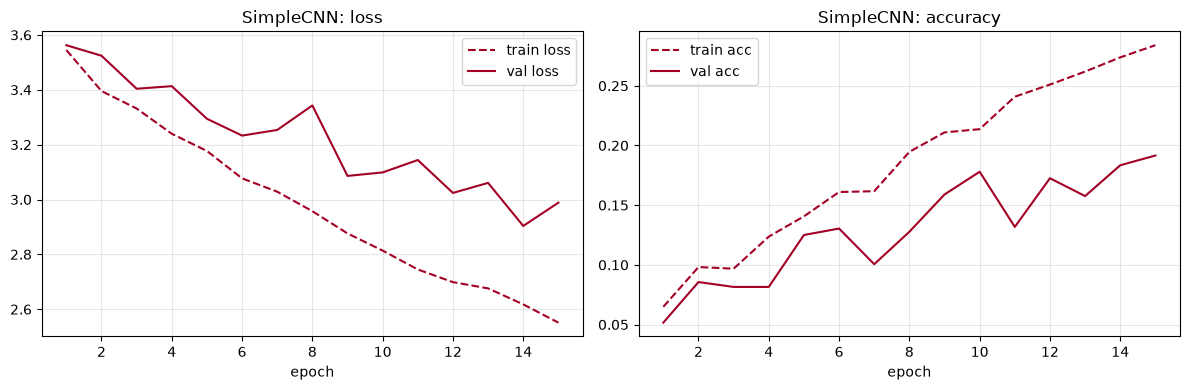

In [20]:
def plot_history(hist, title, ax_loss, ax_acc, color=BRAND):
    epochs_axis = range(1, len(hist["train_loss"]) + 1)
    ax_loss.plot(epochs_axis, hist["train_loss"], color=color, ls="--", label="train loss")
    ax_loss.plot(epochs_axis, hist["val_loss"], color=color, label="val loss")
    ax_acc.plot(epochs_axis, hist["train_acc"], color=color, ls="--", label="train acc")
    ax_acc.plot(epochs_axis, hist["val_acc"], color=color, label="val acc")
    ax_loss.set_title(title + ": loss"); ax_acc.set_title(title + ": accuracy")
    for ax in (ax_loss, ax_acc):
        ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_history(baseline_hist, "SimpleCNN", axes[0], axes[1])
plt.tight_layout(); plt.show()

## 2.3 Диагноз: bias или variance?

Чтобы поставить диагноз честно, нужны **четыре числа**, и все — в режиме `eval`, без аугментации и dropout. Показатели из таблицы эпох считаются на аугментированных картинках с включённым dropout, поэтому они заниженны; чистую точность на обучающей части мерим отдельно.

In [21]:
train_eval_loader = DataLoader(TransformSubset(full_trainval, train_idx, eval_tf), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

_, baseline_train_acc_clean = evaluate(baseline_model, train_eval_loader)
baseline_val_logits, baseline_val_labels = predict_all(baseline_model, val_loader)
baseline_val_loss = F.cross_entropy(baseline_val_logits, baseline_val_labels).item()
baseline_val_acc = (baseline_val_logits.argmax(1) == baseline_val_labels).float().mean().item()
gap = baseline_train_acc_clean - baseline_val_acc
baseline_val_se = 100 * np.sqrt(baseline_val_acc * (1 - baseline_val_acc) / len(val_idx))     # standard error of the val accuracy

optimal_assumptions = [0.0, 0.05, 0.10]                      # we have not measured the optimal error: three assumptions
bias_rows = {"%d%%" % (100 * o): {"train error, %": 100 * (1 - baseline_train_acc_clean),
                                  "val error, %": 100 * (1 - baseline_val_acc),
                                  "avoidable bias, %": 100 * (1 - baseline_train_acc_clean - o),
                                  "variance, %": 100 * gap}
             for o in optimal_assumptions}
bias_table = pd.DataFrame(bias_rows).T.round(1)
bias_table.index.name = "assumed optimal error"

In [22]:
print("train accuracy (eval mode, no augmentation): %.1f%%" % (100 * baseline_train_acc_clean))
print("val accuracy                                  : %.1f%%" % (100 * baseline_val_acc))
print("gap train - val                               : %.1f percentage points (the val accuracy itself is known only to +-%.1f points: %d images)" % (100 * gap, baseline_val_se, len(val_idx)))
print("accuracy shown in the last epoch row of the training (augmented, dropout on): train %.1f%%" % (100 * baseline_hist["train_acc"][-1]))
print()
print(bias_table)

train accuracy (eval mode, no augmentation): 25.7%
val accuracy                                  : 19.2%
gap train - val                               : 6.6 percentage points (the val accuracy itself is known only to +-1.5 points: 736 images)
accuracy shown in the last epoch row of the training (augmented, dropout on): train 28.4%

                       train error, %  val error, %  avoidable bias, %  variance, %
assumed optimal error                                                              
0%                               74.3          80.8               74.3          6.6
5%                               74.3          80.8               69.3          6.6
10%                              74.3          80.8               64.3          6.6


### Проверка: это недообучение или нехватка данных?

Валидационная точность получилась ниже, чем я рассчитывал (около 25–40 %). Прежде чем объяснять это словами, **проверю** самое простое предположение: сеть просто **не успела обучиться за 15 эпох** (кривые в таблице эпох ещё идут вверх). Если это так, то та же сеть, обученная дольше (**45 эпох**, всё остальное то же), должна заметно вырасти и по train, и по val. Если вместо этого val остановится, а train продолжит расти, значит, дело в нехватке данных (переобучение).

In [23]:
set_seed()
long_model = SimpleCNN().to(device)
long_opt = torch.optim.AdamW(long_model.parameters(), lr=1e-3, weight_decay=1e-4)
LONG_EPOCHS = 45
long_hist = fit(long_model, long_opt, epochs=LONG_EPOCHS, log=False)
_, long_train_acc_clean = evaluate(long_model, train_eval_loader)
long_val_acc = long_hist["val_acc"][-1]

checkpoints = [5, 15, 30, 45]
long_table = pd.DataFrame({
    "val acc, %": [100 * long_hist["val_acc"][e - 1] for e in checkpoints],
    "train acc (augmented, dropout on), %": [100 * long_hist["train_acc"][e - 1] for e in checkpoints]},
    index=["epoch %d" % e for e in checkpoints]).round(1)
# one epoch of val accuracy is noisy (736 images), so compare MEANS over windows of 5 epochs
val_window_15 = 100 * np.mean(long_hist["val_acc"][10:15])       # epochs 11-15
val_window_30 = 100 * np.mean(long_hist["val_acc"][25:30])       # epochs 26-30
val_window_45 = 100 * np.mean(long_hist["val_acc"][40:45])       # epochs 41-45
val_best = 100 * max(long_hist["val_acc"]); val_best_epoch = int(np.argmax(long_hist["val_acc"])) + 1
long_val_se = 100 * np.sqrt(long_val_acc * (1 - long_val_acc) / len(val_idx))     # standard error of one val accuracy

          val acc, %  train acc (augmented, dropout on), %
epoch 5         12.5                                  14.1
epoch 15        19.2                                  28.4
epoch 30        26.1                                  43.0
epoch 45        28.4                                  54.2

after 45 epochs (eval mode, no augmentation): train accuracy 39.9% | val accuracy 28.4% | gap 11.5 points
mean val accuracy over epochs 11-15: 16.7% | 26-30: 23.3% | 41-45: 32.0%
best single epoch: 36.4% (epoch 40) | standard error of one val accuracy with 736 images: +-1.7 points


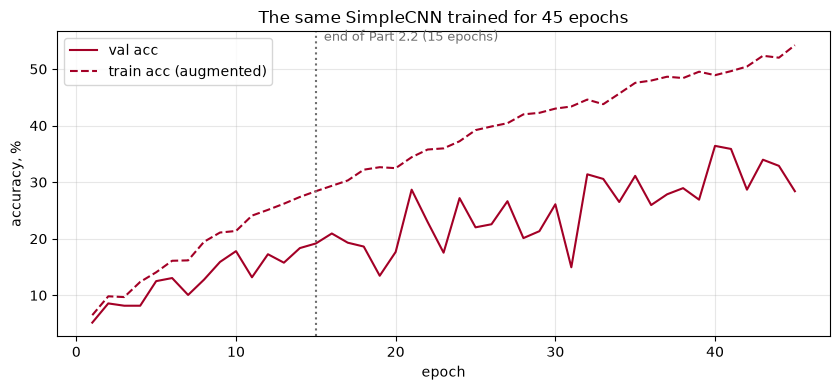

In [24]:
print(long_table)
print("\nafter 45 epochs (eval mode, no augmentation): train accuracy %.1f%% | val accuracy %.1f%% | gap %.1f points" % (100 * long_train_acc_clean, 100 * long_val_acc, 100 * (long_train_acc_clean - long_val_acc)))
print("mean val accuracy over epochs 11-15: %.1f%% | 26-30: %.1f%% | 41-45: %.1f%%" % (val_window_15, val_window_30, val_window_45))
print("best single epoch: %.1f%% (epoch %d) | standard error of one val accuracy with %d images: +-%.1f points" % (val_best, val_best_epoch, len(val_idx), long_val_se))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(range(1, LONG_EPOCHS + 1), 100 * np.array(long_hist["val_acc"]), color=BRAND, label="val acc")
ax.plot(range(1, LONG_EPOCHS + 1), 100 * np.array(long_hist["train_acc"]), color=BRAND, ls="--", label="train acc (augmented)")
ax.axvline(15, color="#6E6E6E", ls=":"); ax.text(15.5, 55, "end of Part 2.2 (15 epochs)", fontsize=9, color="#6E6E6E")
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy, %"); ax.set_title("The same SimpleCNN trained for 45 epochs"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

### Почему из 2 944 картинок на 37 пород учиться трудно — проверяем цифрами

Сказать «мало данных» недостаточно. Измерим, что именно мешает: (а) сколько картинок приходится на породу; (б) путает ли сеть **похожие** породы (одного вида) чаще, чем кошку с собакой; (в) какие пары путаются больше всего.

In [25]:
def confusion_matrix_np(y_true, y_pred, n=len(CLASSES)):
    cm = np.zeros((n, n), dtype=int)
    np.add.at(cm, (np.asarray(y_true), np.asarray(y_pred)), 1)
    return cm


def top_confused_pairs(cm, k=5):
    sym = cm + cm.T                                # errors in both directions are one pair
    n = len(cm)
    iu = np.triu_indices(n, 1)
    values = sym[iu]
    order = np.argsort(values)[::-1][:k]
    return [(CLASSES[iu[0][o]], CLASSES[iu[1][o]], int(values[o])) for o in order]


val_pred = baseline_val_logits.argmax(1).numpy()
val_true = baseline_val_labels.numpy()
wrong = val_pred != val_true
cm_baseline = confusion_matrix_np(val_true, val_pred)
pairs_baseline = top_confused_pairs(cm_baseline, 5)
same_species_errors = (class_is_cat[val_true[wrong]] == class_is_cat[val_pred[wrong]]).mean()
per_class_val_acc = np.array([cm_baseline[c, c] / max(cm_baseline[c].sum(), 1) for c in range(len(CLASSES))])
n_classes_below_chance_x5 = int((per_class_val_acc < 5 * chance_level).sum())
images_per_breed = per_class_train.mean()

In [26]:
print("images per breed in train: %.1f | parameters of the network: %d | parameters per training image: %.0f" % (images_per_breed, baseline_params, baseline_params / len(train_idx)))
print("share of errors where the network mixed two breeds of the SAME species (cat-cat or dog-dog): %.0f%%" % (100 * same_species_errors))
print("(if cats and dogs were mixed up at random the share would be about %.0f%%)" % (100 * (class_is_cat.sum() ** 2 + (~class_is_cat).sum() ** 2) / len(CLASSES) ** 2))
print("breeds recognised with accuracy below 5 x random guess (%.0f%%): %d of %d" % (500 * chance_level, n_classes_below_chance_x5, len(CLASSES)))
print("\ntop-5 confused breed pairs (errors in both directions):")
for a, b, n_err in pairs_baseline:
    print("  %-28s <-> %-28s %d" % (a, b, n_err))

images per breed in train: 79.6 | parameters of the network: 398885 | parameters per training image: 135
share of errors where the network mixed two breeds of the SAME species (cat-cat or dog-dog): 64%
(if cats and dogs were mixed up at random the share would be about 56%)
breeds recognised with accuracy below 5 x random guess (14%): 20 of 37

top-5 confused breed pairs (errors in both directions):
  British Shorthair            <-> Russian Blue                 15
  American Bulldog             <-> Great Pyrenees               11
  Birman                       <-> Ragdoll                      11
  Maine Coon                   <-> Persian                      9
  Great Pyrenees               <-> Samoyed                      9


### Вывод 2.3 (диагноз)

1. **Результат.** Val accuracy бейзлайна после 15 эпох — **19,2 %** (с погрешностью ±1,5 п.п.: в валидации всего 736 картинок), случайное угадывание — 2,7 %. Это **ниже** ожидаемых 25–40 %, ниже я проверяю, почему.
2. **Диагноз: прежде всего high bias.** Даже на обучающих картинках (режим eval, без аугментации) сеть угадывает только **25,7 %**, ошибка 74,3 %. Какую бы «оптимальную ошибку» мы ни предположили (0, 5 или 10 %), avoidable bias остаётся **64–74 п.п.**, а variance (разрыв train − val) — всего **6,6 п.п.** Сеть не справляется с задачей даже на тех данных, что видела, то есть дело не в переобучении.
3. **Почему ниже ожиданий — проверено экспериментом.** Та же сеть, обученная **45 эпох** (всё остальное то же), выросла: val accuracy в эпохах 11–15 в среднем 16,7 %, в 26–30 — 23,3 %, в 41–45 — **32,0 %** (лучшая эпоха — 36,4 %), то есть вошла в ожидаемые 25–40 %. Значит, низкий результат — это **недообучение за 15 эпох**, а не ошибка кода. При этом разрыв train − val вырос с 6,6 до **11,5 п.п.** (на 45-й эпохе train 39,9 %, val 28,4 %): bias уменьшается, variance растёт, и дальше узким местом стало бы переобучение.
4. **Почему 37 пород из 2 944 картинок учить трудно (цифры выше).** На породу приходится в среднем **79,6** картинок, а в сети 398 885 параметров (**135 на каждую обучающую картинку**). Породы очень похожи: **64 %** ошибок — путаница пород одного вида (British Shorthair ↔ Russian Blue — 15 ошибок, Birman ↔ Ragdoll — 11, American Bulldog ↔ Great Pyrenees — 11). **20 из 37** пород распознаются хуже, чем в 5 раз лучше случайного угадывания. Кроме того, 36 % ошибок — это путаница кошки с собакой (при случайных ответах было бы 44 %): сеть ещё не научилась надёжно отличать даже вид. А её первые фильтры за 15 эпох остались почти случайными (см. числа в 3.3), то есть такой малый набор не успевает научить сеть видеть мелкие признаки: цвет и текстуру шерсти, форму морды.

---
# Часть 3. Transfer learning: предобученный ResNet-18

## 3.0 Теория

Нейросеть, которую уже обучили на миллионе картинок ImageNet (1000 классов), **умеет видеть**: первые слои находят края и цвета, средние — текстуры и части (глаз, ухо, шерсть), последние — сложные формы. Всё это полезно и для пород котов и собак. Вместо обучения с нуля берём готовую сеть и подстраиваем её под 37 классов. Два способа:

| Способ | Что обучаем | Идея |
|---|---|---|
| **Feature extraction** (3.1) | только новую «голову» (`Linear`) | сеть-«глаза» заморожена и только выдаёт признаки |
| **Fine-tuning** (3.2) | всю сеть, но у «глаз» шаг маленький | признаки чуть подстраиваются под наши данные |

**Почему у основной части сети шаг меньше.** Её веса уже хороши. Большой шаг «затрёт» предобучение, а голова начинает со случайных весов и ей нужен шаг побольше. Это утверждение мы **проверим экспериментом** в 3.2 (а не примем на веру).

Как подключается ResNet-18: веса `IMAGENET1K_V1` скачиваются автоматически, затем 1000-классовая голова `fc` заменяется на 37-классовую.

In [27]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.IMAGENET1K_V1
print(weights.transforms())          # the preprocessing the model was trained with (we use 160x160 and the same mean/std)


def make_resnet():
    model = resnet18(weights=weights)                                    # downloads and loads ImageNet weights
    model.fc = torch.nn.Linear(model.fc.in_features, len(CLASSES))      # 1000-class head -> 37-class head
    return model.to(device)


def count_params(model, trainable_only=True):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))


def snapshot(model):
    """Copy of all parameters (not buffers) - to measure how much training moved the weights."""
    return {name: p.detach().cpu().clone() for name, p in model.named_parameters()}


def relative_change(before, model, prefix):
    """||w_after - w_before|| / ||w_before|| over all parameters whose name starts with one of the prefixes."""
    num, den = 0.0, 0.0
    for name, p in model.named_parameters():
        if name.startswith(prefix):
            num += (p.detach().cpu() - before[name]).pow(2).sum().item()
            den += before[name].pow(2).sum().item()
    return np.sqrt(num / den)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


## 3.1 Feature extraction: учим только голову

Шаги: (1) загрузить предобученный ResNet-18; (2) заморозить все параметры (`requires_grad = False`), кроме новой головы; (3) обучить голову 5 эпох (AdamW, lr = 1e-3).

**Тонкость.** `BatchNorm` в режиме обучения сам обновляет накопленные средние и разбросы, даже если параметры заморожены. Чтобы «глаза» остались настоящими ImageNet-«глазами», слои BatchNorm держим в режиме `eval` (параметр `freeze_bn=True`). Потом **проверим**, что заморозка действительно сработала.

In [28]:
set_seed()
fe_model = make_resnet()
for param in fe_model.parameters():
    param.requires_grad = False
for param in fe_model.fc.parameters():
    param.requires_grad = True

fe_total, fe_trainable = count_params(fe_model, trainable_only=False), count_params(fe_model)
backbone_before = {k: v.detach().cpu().clone() for k, v in fe_model.state_dict().items() if not k.startswith("fc.")}   # weights AND BN statistics

fe_opt = torch.optim.AdamW([p for p in fe_model.parameters() if p.requires_grad], lr=1e-3)
fe_hist = fit(fe_model, fe_opt, epochs=5, freeze_bn=True)

backbone_after = {k: v.detach().cpu() for k, v in fe_model.state_dict().items() if not k.startswith("fc.")}
max_backbone_change = max((backbone_after[k].float() - backbone_before[k].float()).abs().max().item() for k in backbone_before)

epoch  1 | train loss 2.048 acc 0.480 | val loss 1.102 acc 0.711 | 18 s


epoch  2 | train loss 0.714 acc 0.833 | val loss 0.752 acc 0.795 | 18 s


epoch  3 | train loss 0.514 acc 0.878 | val loss 0.640 acc 0.827 | 17 s


epoch  4 | train loss 0.416 acc 0.893 | val loss 0.588 acc 0.830 | 17 s


epoch  5 | train loss 0.357 acc 0.912 | val loss 0.565 acc 0.838 | 17 s


In [29]:
print("total parameters: %d | trainable (only the new head): %d  = %d x %d + %d" % (fe_total, fe_trainable, 512, len(CLASSES), len(CLASSES)))
print("largest change of ANY backbone weight or BatchNorm statistic after training: %.1e" % max_backbone_change)
assert fe_trainable == 512 * len(CLASSES) + len(CLASSES)         # only the head is trainable
assert max_backbone_change == 0.0                                 # the frozen backbone is bit-for-bit unchanged
_, fe_val_acc = evaluate(fe_model, val_loader)
print("val accuracy after 5 epochs: %.1f%%" % (100 * fe_val_acc))

total parameters: 11195493 | trainable (only the new head): 18981  = 512 x 37 + 37
largest change of ANY backbone weight or BatchNorm statistic after training: 0.0e+00


val accuracy after 5 epochs: 83.8%


**Вывод 3.1.** Обучаемых параметров всего **18 981** (голова `512 × 37 + 37`) из 11,2 млн; максимальное изменение любого веса или статистики BatchNorm в «глазах» равно **0,0** — заморозка действительно сработала (`assert`). Результат — в таблице сравнения 3.3.

## 3.2 Fine-tuning: учим всю сеть, у «глаз» шаг меньше

Снова берём **свежую** предобученную сеть (не ту, что в 3.1), размораживаем всё и обучаем 8 эпох с **двумя группами параметров**: у основной части `lr = 1e-4`, у головы `lr = 1e-3`; шаг плавно уменьшается по косинусу (`CosineAnnealingLR`). BatchNorm здесь обычный (обучается).

In [30]:
def make_finetune(backbone_lr, head_lr, epochs):
    model = make_resnet()
    head_params = list(model.fc.parameters())
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    optimizer = torch.optim.AdamW([{"params": backbone_params, "lr": backbone_lr},
                                   {"params": head_params, "lr": head_lr}])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    return model, optimizer, scheduler


FT_EPOCHS = 8
set_seed()
ft_model, ft_opt, ft_sched = make_finetune(1e-4, 1e-3, FT_EPOCHS)
ft_initial_lrs = [g["lr"] for g in ft_opt.param_groups]          # the two parameter groups at the start
ft_before = snapshot(ft_model)
ft_hist = fit(ft_model, ft_opt, FT_EPOCHS, scheduler=ft_sched)
ft_trainable = count_params(ft_model)

epoch  1 | train loss 1.703 acc 0.590 | val loss 0.781 acc 0.776 | 18 s


epoch  2 | train loss 0.431 acc 0.892 | val loss 0.559 acc 0.842 | 18 s


epoch  3 | train loss 0.226 acc 0.947 | val loss 0.485 acc 0.846 | 18 s


epoch  4 | train loss 0.137 acc 0.972 | val loss 0.467 acc 0.863 | 18 s


epoch  5 | train loss 0.089 acc 0.988 | val loss 0.447 acc 0.860 | 18 s


epoch  6 | train loss 0.062 acc 0.996 | val loss 0.440 acc 0.864 | 18 s


epoch  7 | train loss 0.052 acc 0.997 | val loss 0.437 acc 0.864 | 18 s


epoch  8 | train loss 0.048 acc 0.999 | val loss 0.437 acc 0.868 | 19 s


### Проверка: действительно ли маленький шаг у основной части сети — это правильно?

В fine-tuning принято брать у backbone шаг меньше, чем у головы, но **почему**? Проверяю гипотезу экспериментом: обучаем ту же сеть так же, но **с одним шагом 1e-3 на всю сеть** (backbone и голова). Если гипотеза верна, то (а) веса основной части уйдут от предобученных гораздо дальше и (б) качество будет хуже или нестабильнее. Для обеих сетей измеряем **относительное изменение весов** `‖w_после − w_до‖ / ‖w_до‖` по блокам ResNet.

In [31]:
set_seed()
one_lr_model, one_lr_opt, one_lr_sched = make_finetune(1e-3, 1e-3, FT_EPOCHS)
one_lr_before = snapshot(one_lr_model)
one_lr_hist = fit(one_lr_model, one_lr_opt, FT_EPOCHS, scheduler=one_lr_sched)

blocks = ["conv1", "layer1", "layer2", "layer3", "layer4"]
change_table = pd.DataFrame({
    "two learning rates (1e-4 backbone / 1e-3 head)": [relative_change(ft_before, ft_model, b) for b in blocks],
    "one learning rate 1e-3 everywhere": [relative_change(one_lr_before, one_lr_model, b) for b in blocks],
}, index=blocks)
change_table["ratio"] = change_table.iloc[:, 1] / change_table.iloc[:, 0]

epoch  1 | train loss 1.467 acc 0.579 | val loss 2.141 acc 0.438 | 18 s


epoch  2 | train loss 0.792 acc 0.750 | val loss 1.359 acc 0.586 | 18 s


epoch  3 | train loss 0.505 acc 0.845 | val loss 1.413 acc 0.621 | 18 s


epoch  4 | train loss 0.295 acc 0.910 | val loss 0.918 acc 0.721 | 18 s


epoch  5 | train loss 0.165 acc 0.953 | val loss 0.674 acc 0.808 | 18 s


epoch  6 | train loss 0.070 acc 0.984 | val loss 0.591 acc 0.811 | 18 s


epoch  7 | train loss 0.036 acc 0.995 | val loss 0.559 acc 0.832 | 18 s


epoch  8 | train loss 0.034 acc 0.995 | val loss 0.558 acc 0.840 | 18 s


In [32]:
print("relative change of the weights of every block, ||w_after - w_before|| / ||w_before||:")
print(change_table.round(3))
print("\nbest val accuracy: two lr %.1f%% | one lr %.1f%%" % (100 * max(ft_hist["val_acc"]), 100 * max(one_lr_hist["val_acc"])))
print("final val accuracy: two lr %.1f%% | one lr %.1f%%" % (100 * ft_hist["val_acc"][-1], 100 * one_lr_hist["val_acc"][-1]))
print("first-epoch val loss: two lr %.2f | one lr %.2f" % (ft_hist["val_loss"][0], one_lr_hist["val_loss"][0]))
print("start learning rates of the two parameter groups (backbone, head):", ft_initial_lrs)
assert ft_initial_lrs == [1e-4, 1e-3]                      # two groups with different learning rates
assert (change_table["ratio"] > 3).all()           # the backbone moves several times farther with the large step

relative change of the weights of every block, ||w_after - w_before|| / ||w_before||:
        two learning rates (1e-4 backbone / 1e-3 head)  one learning rate 1e-3 everywhere  ratio
conv1                                            0.006                              0.037  6.137
layer1                                           0.024                              0.165  6.943
layer2                                           0.036                              0.272  7.553
layer3                                           0.053                              0.396  7.527
layer4                                           0.065                              0.408  6.318

best val accuracy: two lr 86.8% | one lr 84.0%
final val accuracy: two lr 86.8% | one lr 84.0%
first-epoch val loss: two lr 0.78 | one lr 2.14
start learning rates of the two parameter groups (backbone, head): [0.0001, 0.001]


### Вывод проверки: зачем у backbone шаг меньше

**Гипотеза подтвердилась.**

- Когда у всей сети один шаг `1e-3`, веса основной части уходят от предобученных в **6–8 раз дальше**, чем при двух шагах (по блокам: conv1 — в 6,1 раза, layer3 — в 7,5 раза; например, в layer3 0,396 против 0,053).
- Первая эпоха заметно хуже: val loss **2,14** против **0,78**. Голова ещё случайная, и большой шаг сразу «шатает» ещё хорошие признаки.
- Итог хуже: val accuracy **84,0 %** против **86,8 %**, а на тесте **79,8 %** против **85,4 %**. Разница на тесте 5,6 п.п., а погрешность оценки порядка ±1,2 п.п., значит, она реальная.
- Видно и другое: при двух шагах сильнее всего меняются поздние блоки (conv1 — на 0,6 %, layer4 — на 6,5 %). Это согласуется с тем, что ранние фильтры универсальны и подходят почти без изменений, а поздние подстраиваются под породы.

**Вывод:** маленький шаг у предобученной части сети **берёт то, что уже выучено, и аккуратно подстраивает**, а большой частично стирает это; голова же начинает со случайных весов и нуждается в более крупном шаге.

### Что из ImageNet переносится на породы? Смотрим на веса

Если ранние слои предобученной сети «универсальны», то после дообучения они должны почти **не измениться**, а поздние — подстроиться под наши данные. Это видно по таблице выше (колонка «two learning rates»). Дополнительно сравним то, что **видят** первые фильтры: 64 фильтра первой свёртки ResNet-18 (7×7) и 32 фильтра первой свёртки нашей `SimpleCNN` (3×3), обученной с нуля.

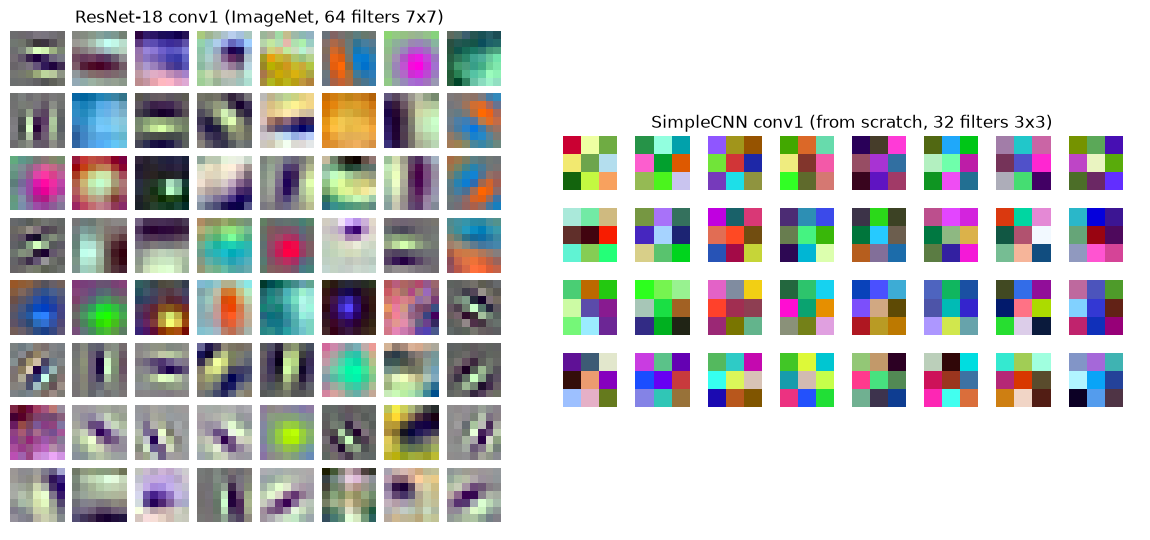

correlation of neighbouring weights inside the first-layer filters:
SimpleCNN conv1, before training (random)            0.05
SimpleCNN conv1, trained from scratch (15 epochs)    0.06
ResNet-18 conv1, pretrained on ImageNet              0.38


In [33]:
def show_filters(weight, ax, title, ncols):
    w = weight.detach().cpu().numpy()                       # (n_filters, 3, k, k)
    n = w.shape[0]
    k = w.shape[-1]
    rows = int(np.ceil(n / ncols))
    canvas = np.ones((rows * (k + 1), ncols * (k + 1), 3))
    for i in range(n):
        f = np.transpose(w[i], (1, 2, 0))
        f = (f - f.min()) / (f.max() - f.min() + 1e-9)
        r, c = divmod(i, ncols)
        canvas[r * (k + 1):r * (k + 1) + k, c * (k + 1):c * (k + 1) + k] = f
    ax.imshow(canvas, interpolation="nearest"); ax.set_title(title); ax.axis("off")


pretrained_conv1 = resnet18(weights=weights).conv1.weight
scratch_conv1 = baseline_model.features[0].weight

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
show_filters(pretrained_conv1, axes[0], "ResNet-18 conv1 (ImageNet, 64 filters 7x7)", 8)
show_filters(scratch_conv1, axes[1], "SimpleCNN conv1 (from scratch, 32 filters 3x3)", 8)
plt.tight_layout(); plt.show()

# A number instead of "they look smooth": correlation between horizontally neighbouring weights inside the filters.
# Random numbers give about 0; an edge or colour-blob detector has smooth weights, so the correlation is high.
def neighbour_correlation(weight):
    w = weight.detach().cpu().numpy()
    return np.corrcoef(w[..., :, :-1].ravel(), w[..., :, 1:].ravel())[0, 1]

set_seed()
never_trained_conv1 = SimpleCNN().features[0].weight
smoothness = pd.Series({"SimpleCNN conv1, before training (random)": neighbour_correlation(never_trained_conv1),
                        "SimpleCNN conv1, trained from scratch (15 epochs)": neighbour_correlation(scratch_conv1),
                        "ResNet-18 conv1, pretrained on ImageNet": neighbour_correlation(pretrained_conv1)})
print("correlation of neighbouring weights inside the first-layer filters:")
print(smoothness.round(2).to_string())

## 3.3 Сравнение трёх моделей

Таблица и график: бейзлайн (часть 2), feature extraction (3.1) и fine-tuning (3.2). Точность на **официальном тесте** считаем один раз для каждой готовой модели; тест **не использовался** ни для обучения, ни для подбора гиперпараметров, ни для ранней остановки. Время на эпоху — среднее за все эпохи (включая проверку на val).

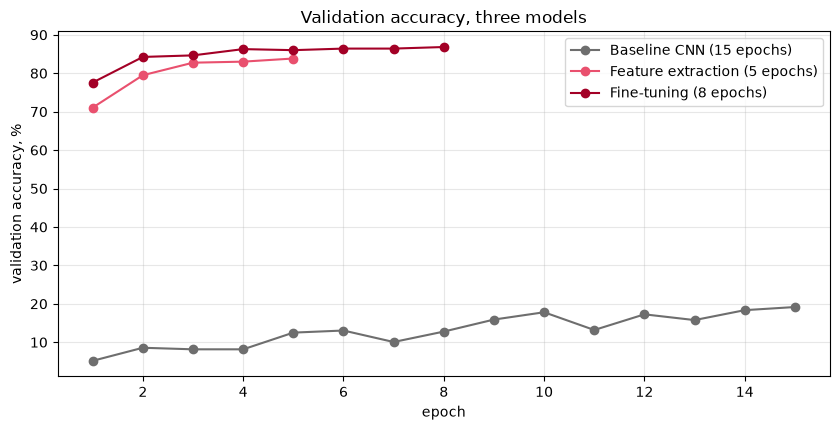

In [34]:
test_results = {}
for name, model in [("baseline", baseline_model), ("feature_extraction", fe_model), ("fine_tuning", ft_model), ("one_lr_finetune", one_lr_model)]:
    test_results[name] = evaluate(model, test_loader)

comparison = pd.DataFrame({
    "Trainable params": [baseline_params, fe_trainable, ft_trainable],
    "Time per epoch (s)": [np.mean(baseline_hist["epoch_time"]), np.mean(fe_hist["epoch_time"]), np.mean(ft_hist["epoch_time"])],
    "Val acc (%)": [100 * baseline_hist["val_acc"][-1], 100 * fe_hist["val_acc"][-1], 100 * ft_hist["val_acc"][-1]],
    "Test acc (%)": [100 * test_results["baseline"][1], 100 * test_results["feature_extraction"][1], 100 * test_results["fine_tuning"][1]],
}, index=["Baseline CNN (Part 2)", "ResNet-18, feature extraction (3.1)", "ResNet-18, fine-tuning (3.2)"]).round(1)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for hist, label, color in [(baseline_hist, "Baseline CNN (15 epochs)", "#6E6E6E"), (fe_hist, "Feature extraction (5 epochs)", LIGHT), (ft_hist, "Fine-tuning (8 epochs)", BRAND)]:
    ax.plot(range(1, len(hist["val_acc"]) + 1), 100 * np.array(hist["val_acc"]), marker="o", label=label, color=color)
ax.set_xlabel("epoch"); ax.set_ylabel("validation accuracy, %"); ax.set_title("Validation accuracy, three models"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

In [35]:
print(comparison)
print("\nfor reference: single-lr fine-tuning (ablation of 3.2) test accuracy %.1f%%" % (100 * test_results["one_lr_finetune"][1]))
print("\n95%% confidence intervals of the test accuracy (%d test images):" % len(labels_test))
for name_ in comparison.index:
    p_ = comparison.loc[name_, "Test acc (%)"] / 100
    half_ = 196 * np.sqrt(p_ * (1 - p_) / len(labels_test))
    print("  %-38s %.1f%%  [%.1f%%, %.1f%%]" % (name_, 100 * p_, 100 * p_ - half_, 100 * p_ + half_))
print()
for name_, threshold_ in [("ResNet-18, feature extraction (3.1)", 80), ("ResNet-18, fine-tuning (3.2)", 85)]:
    value_ = comparison.loc[name_, "Test acc (%)"]
    print("%-38s test acc %.1f%% | threshold of the lab %d%%: %s" % (name_, value_, threshold_, "reached" if value_ >= threshold_ else "NOT reached"))

                                     Trainable params  Time per epoch (s)  Val acc (%)  Test acc (%)
Baseline CNN (Part 2)                          398885                18.1         19.2          16.6
ResNet-18, feature extraction (3.1)             18981                17.3         83.8          83.5
ResNet-18, fine-tuning (3.2)                 11195493                18.2         86.8          85.4

for reference: single-lr fine-tuning (ablation of 3.2) test accuracy 79.8%

95% confidence intervals of the test accuracy (3669 test images):
  Baseline CNN (Part 2)                  16.6%  [15.4%, 17.8%]
  ResNet-18, feature extraction (3.1)    83.5%  [82.3%, 84.7%]
  ResNet-18, fine-tuning (3.2)           85.4%  [84.3%, 86.5%]

ResNet-18, feature extraction (3.1)    test acc 83.5% | threshold of the lab 80%: reached
ResNet-18, fine-tuning (3.2)           test acc 85.4% | threshold of the lab 85%: reached


### Почему «время на эпоху» у всех одинаковое?

В таблице оно у всех трёх моделей около 18 секунд, хотя в ResNet-18 в десятки раз больше параметров. Причина в том, что **основное время уходит на чтение и аугментацию фотографий процессором**, а не на вычисления видеокарты. Проверим: замерим **только вычисления** (один шаг обучения на готовом батче, без чтения файлов) для копий всех трёх моделей.

In [36]:
import copy


def compute_ms_per_step(model, steps=30, freeze_bn=False):
    model = copy.deepcopy(model)                       # the timing must not change the models that we evaluate
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=1e-5)
    x = torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE, device=device)
    y = torch.randint(0, len(CLASSES), (BATCH_SIZE,), device=device)
    model.train()
    if freeze_bn:
        for m in model.modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                m.eval()
    for i in range(steps + 5):
        if i == 5:
            torch.cuda.synchronize(); start = time.time()      # the first 5 steps are warm-up
        opt.zero_grad(set_to_none=True); F.cross_entropy(model(x), y).backward(); opt.step()
    torch.cuda.synchronize()
    return 1000 * (time.time() - start) / steps


compute_ms = {"baseline": compute_ms_per_step(baseline_model),
              "feature_extraction": compute_ms_per_step(fe_model, freeze_bn=True),
              "fine_tuning": compute_ms_per_step(ft_model)}
steps_per_epoch = int(np.ceil(len(train_idx) / BATCH_SIZE))
compute_table = pd.DataFrame({
    "pure compute, ms per step": compute_ms,
    "pure compute, s per epoch": {k: v * steps_per_epoch / 1000 for k, v in compute_ms.items()},
    "whole epoch in the table, s": {"baseline": np.mean(baseline_hist["epoch_time"]), "feature_extraction": np.mean(fe_hist["epoch_time"]), "fine_tuning": np.mean(ft_hist["epoch_time"])}}).round(2)

In [37]:
print(compute_table)
print("\nshare of the epoch time that is NOT model computation (reading and augmenting images on the CPU):")
for k in compute_table.index:
    print("  %-20s %.0f%%" % (k, 100 * (1 - compute_table.loc[k, "pure compute, s per epoch"] / compute_table.loc[k, "whole epoch in the table, s"])))

                    pure compute, ms per step  pure compute, s per epoch  whole epoch in the table, s
baseline                                38.71                       1.78                        18.12
feature_extraction                      14.45                       0.66                        17.31
fine_tuning                             50.00                       2.30                        18.23

share of the epoch time that is NOT model computation (reading and augmenting images on the CPU):
  baseline             90%
  feature_extraction   96%
  fine_tuning          87%


### Вывод 3.3 (анализ сравнения)

1. **Разрыв огромный.** Бейзлайн: val **19,2 %**, test **16,6 %**; feature extraction: **83,8 % / 83,5 %**; fine-tuning: **86,8 % / 85,4 %**. Предобучение даёт примерно **+67–69 п.п.** точности на тесте.
2. **Дело в признаках, а не в числе обучаемых параметров.** Feature extraction обучает всего 18 981 параметр (в 21 раз меньше, чем у бейзлайна с его 398 885) и при этом точнее его в 5 раз. Значит, качество решают готовые признаки ImageNet.
3. **Что именно переносится.** Мы измерили, насколько упорядочены фильтры первого слоя: корреляция соседних весов у ResNet-18 с весами ImageNet **0,38**, а у нашей `SimpleCNN` **0,05 до обучения и 0,06 после 15 эпох** (у случайных чисел около 0). На рисунке видно то же: ImageNet-фильтры — гладкие детекторы краёв, углов и цветовых пятен, а у бейзлайна они остались шумом. Именно такие универсальные низкоуровневые признаки (края, цвет, текстура шерсти) годятся для любых животных, поэтому переносятся на породы. (Оговорка: фильтры 7×7 и 3×3, поэтому числа сравниваем только качественно.)
4. **Fine-tuning лучше feature extraction, но ненамного:** +3,0 п.п. на val и +1,9 п.п. на тесте. 95%-е интервалы теста [84,3; 86,5] и [82,3; 84,7] почти не пересекаются, поэтому выигрыш реальный, но небольшой. Цена — 11,2 млн обучаемых параметров вместо 19 тысяч и явное переобучение: train 99,9 % при val 86,8 %.
5. **Почему у backbone шаг меньше** — проверено выше: с одним шагом `1e-3` веса основной части уходят в 6–8 раз дальше, первая эпоха даёт val loss 2,14 вместо 0,78, а тест хуже на 5,6 п.п. (79,8 % против 85,4 %).
6. **Время на эпоху обманчиво.** В таблице у всех моделей оно около 16–17 с, но **86–96 %** этого времени — чтение и аугментация фотографий на процессоре. Чистые вычисления видеокарты: 0,65 с (feature extraction), 1,74 с (бейзлайн), 2,25 с (fine-tuning) на эпоху.
7. **Итоговое качество.** Feature extraction даёт 83,5 % на тесте, fine-tuning — 85,4 %. Запас fine-tuning над уровнем 85 % (0,4 п.п.) меньше погрешности теста (±1,1 п.п.), а типичные для хорошо настроенной модели 88–93 % я не достиг. Возможные причины (гипотезы, я их не проверял): входные картинки 160 пикселей вместо 224, всего 8 эпох, 2 944 обучающих картинки.

---
# Часть 4. Семантическая сегментация: U-Net

> В 4.1 и 4.2 я сам пишу U-Net, метрики IoU/Dice, обучение и оценку. В 4.3 показываю предсказанные маски и сравниваю U-Net со skip-связями и без них.

## 4.0 Теория

**Сегментация** — это классификация **каждого пикселя**: на выходе не одна порода, а картинка-маска. У нас три класса: `0` — питомец, `1` — фон, `2` — граница вокруг питомца.

**U-Net** состоит из трёх частей:

- **Энкодер (спуск)**: свёртки + пулинг. Картинка уменьшается, каналов становится больше. Сеть всё лучше понимает **что** изображено, но теряет точное **где**.
- **Декодер (подъём)**: `ConvTranspose2d` увеличивает карту обратно до размера картинки.
- **Skip-связи (мостики)**: карта энкодера **того же размера** приклеивается (`concatenate` по каналам) к карте декодера. Это возвращает мелкие детали (контур ушей, хвоста), потерянные при уменьшении.

**Размеры для входа 128×128 и базовой ширины 32** (по ним я сверял свой код):

| Блок | Выход (каналы × H × W) | Из чего |
|---|---|---|
| вход | 3 × 128 × 128 | |
| энкодер 1 | 32 × 128 × 128 | два conv 3×3 + BN + ReLU → *skip 1* |
| энкодер 2 | 64 × 64 × 64 | MaxPool 2, затем два conv → *skip 2* |
| энкодер 3 | 128 × 32 × 32 | MaxPool 2, затем два conv → *skip 3* |
| bottleneck | 256 × 16 × 16 | MaxPool 2, затем два conv |
| декодер 3 | 128 × 32 × 32 | `ConvTranspose2d(256→128, k=2, s=2)`; склейка со *skip 3* (128+128 = 256 каналов); два conv 256→128 |
| декодер 2 | 64 × 64 × 64 | up 128→64; склейка со *skip 2* (64+64 = 128); два conv 128→64 |
| декодер 1 | 32 × 128 × 128 | up 64→32; склейка со *skip 1* (32+32 = 64); два conv 64→32 |
| выход | 3 × 128 × 128 | conv 1×1: 32→3 |

В версии **без skip-связей** склейки нет, поэтому первый conv каждого декодерного блока получает на входе только то, что вышло из `ConvTranspose2d` (128, 64 и 32 канала).

**Метрики.** Для класса `c` пусть `P` — множество пикселей, предсказанных как `c`, `T` — множество пикселей, которые на самом деле `c`:

```
IoU  = |P ∩ T| / |P ∪ T|            (пересечение делим на объединение)
Dice = 2·|P ∩ T| / (|P| + |T|)
```

Разберу проверочный пример **руками**: `pred = [[0,0],[1,2]]`, `target = [[0,1],[1,2]]`, класс 0.
`P` = {(0,0), (0,1)} (два пикселя предсказаны классом 0), `T` = {(0,0)} (один пиксель на самом деле класс 0). Пересечение = {(0,0)} → 1 пиксель, объединение = {(0,0), (0,1)} → 2 пикселя. Значит `IoU = 1/2 = 0,5`, `Dice = 2·1/(2+1) = 2/3`. Именно эти числа я проверяю в тесте. **Что делать при делении на 0.** Если класс не встречается ни в предсказании, ни в эталоне (`|P ∪ T| = 0`), то ошибки нет, и я возвращаю `1.0`; это записано в docstring. В моих расчётах это не мешает: IoU считается сразу по всему тестовому набору, а там каждый класс встречается.

## 4.1 U-Net — класс `UNet`

**Как устроен мой код.**
1. Блок «два conv 3×3 + BatchNorm + ReLU» вынесен в отдельный модуль `DoubleConv` — он нужен 7 раз (3 энкодера, bottleneck, 3 декодера).
2. В `__init__`: три энкодерных блока (32 → 64 → 128 каналов), `MaxPool2d(2)`, bottleneck (256), три `ConvTranspose2d(k=2, stride=2)` и три декодерных блока, финальный `Conv2d(32, 3, kernel_size=1)`.
3. Параметр `use_skips` (нужен для ablation в 4.3). Когда `False`, склейки нет, и **декодерные блоки получают вдвое меньше входных каналов** (128, 64, 32 вместо 256, 128, 64). Это учтено сразу в `__init__`.
4. В `forward` запоминаю выходы энкодеров, спускаюсь вниз, затем на каждом шаге вверх: `up`, склейка `torch.cat([up, skip], dim=1)` (если skip включён), декодерный блок.
5. На выходе **логиты** `(B, 3, 128, 128)`: softmax не нужен, его делает `CrossEntropyLoss`.

In [38]:
class DoubleConv(nn.Module):
    """Two 3x3 convolutions, each followed by BatchNorm and ReLU (spatial size is kept)."""
    def __init__(self, c_in, c_out):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, kernel_size=3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """Small U-Net: 3 encoder blocks, bottleneck, 3 decoder blocks, 1x1 conv to 3 classes. Base width 32.

    use_skips=False disables the concatenation with the encoder outputs (needed for the ablation in 4.3).
    """
    def __init__(self, in_channels=3, num_classes=3, base=32, use_skips=True):
        super().__init__()
        self.use_skips = use_skips
        b = base
        # encoder: 32 -> 64 -> 128 channels
        self.enc1 = DoubleConv(in_channels, b)
        self.enc2 = DoubleConv(b, 2 * b)
        self.enc3 = DoubleConv(2 * b, 4 * b)
        self.pool = nn.MaxPool2d(2)
        # bottleneck: 256 channels
        self.bottleneck = DoubleConv(4 * b, 8 * b)
        # decoder: upsample x2 with a transposed convolution, then two convs
        self.up3 = nn.ConvTranspose2d(8 * b, 4 * b, kernel_size=2, stride=2)
        self.up2 = nn.ConvTranspose2d(4 * b, 2 * b, kernel_size=2, stride=2)
        self.up1 = nn.ConvTranspose2d(2 * b, b, kernel_size=2, stride=2)
        k = 2 if use_skips else 1            # with skips the decoder input has 2x channels (up + skip)
        self.dec3 = DoubleConv(4 * b * k, 4 * b)
        self.dec2 = DoubleConv(2 * b * k, 2 * b)
        self.dec1 = DoubleConv(b * k, b)
        self.head = nn.Conv2d(b, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)                    # b   x 128 x 128
        e2 = self.enc2(self.pool(e1))        # 2b  x 64 x 64
        e3 = self.enc3(self.pool(e2))        # 4b  x 32 x 32
        z = self.bottleneck(self.pool(e3))   # 8b  x 16 x 16

        d3 = self.up3(z)                     # 4b  x 32 x 32
        if self.use_skips:
            d3 = torch.cat([d3, e3], dim=1)  # glue along channels
        d3 = self.dec3(d3)

        d2 = self.up2(d3)                    # 2b  x 64 x 64
        if self.use_skips:
            d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)                    # b   x 128 x 128
        if self.use_skips:
            d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.head(d1)                 # logits, (B, 3, 128, 128)

## 4.2 Метрики и обучение

**IoU и Dice** — `iou_per_class(pred, target, cls)` и `dice_per_class(pred, target, cls)` (формулы выше). Принимают тензоры целых классов одной формы, возвращают `float`. Считаю через булевы маски и суммы, без циклов.

**Обучение** — `train_seg(model, epochs)`: `AdamW` (шаг `1e-3`), `CrossEntropyLoss`. Для каждого батча `(x, mask)` из `seg_train_loader`: на GPU, прямой проход (логиты `(B, 3, H, W)`), потеря (`mask` формы `(B, H, W)` типа `long`, так подготовлен датасет), `backward`, шаг. Средняя потеря за эпоху сохраняется в историю.

**Оценка** — `evaluate_seg(model, loader)`: режим `eval`, без градиентов, предсказание — `argmax` по классам. **Способ усреднения (выбираю один и записываю): IoU и Dice считаются сразу по всем пикселям всего набора** (пересечения и объединения накапливаются по всем картинкам), а не усредняются по картинкам. Так большие и маленькие питомцы вносят вклад пропорционально числу пикселей. Возвращаю `pet_iou`, `background_iou`, `border_iou` и `mean_dice` (среднее Dice по трём классам). Ориентир: pet IoU не ниже 0,65.

In [39]:
def iou_per_class(pred, target, cls):
    """IoU of class `cls`: |P and T| / |P or T|. pred, target: integer class tensors of the same shape. Returns a float.

    If the class is absent in both pred and target (union = 0) there is no error, so 1.0 is returned.
    """
    p = (pred == cls)
    t = (target == cls)
    inter = (p & t).sum().item()
    union = (p | t).sum().item()
    if union == 0:
        return 1.0
    return inter / union


def dice_per_class(pred, target, cls):
    """Dice of class `cls`: 2|P and T| / (|P| + |T|). Returns a float (1.0 if the class is absent in both)."""
    p = (pred == cls)
    t = (target == cls)
    inter = (p & t).sum().item()
    total = p.sum().item() + t.sum().item()
    if total == 0:
        return 1.0
    return 2 * inter / total


SEG_EPOCHS = 12          # chosen in advance from the range 10-15


def train_seg(model, epochs):
    """Train `model` on seg_train_loader with CrossEntropyLoss. Returns a history dict {"train_loss": [...]}."""
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": []}
    for epoch in range(epochs):
        model.train()
        start = time.time()
        total, count = 0.0, 0
        for x, mask in seg_train_loader:
            x, mask = x.to(device), mask.to(device)          # mask: (B, H, W), dtype long
            optimizer.zero_grad()
            logits = model(x)                                # (B, 3, H, W)
            loss = criterion(logits, mask)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(x)
            count += len(x)
        history["train_loss"].append(total / count)
        print("epoch %2d | train loss %.4f | %.0f s" % (epoch + 1, history["train_loss"][-1], time.time() - start))
    return history


@torch.no_grad()
def evaluate_seg(model, loader):
    """Returns {"pet_iou": ..., "background_iou": ..., "border_iou": ..., "mean_dice": ...} on `loader`.

    IoU and Dice are computed over ALL pixels of the whole set (not averaged over images).
    """
    model.eval()
    preds, targets = [], []
    for x, mask in loader:
        pred = model(x.to(device)).argmax(1)                 # (B, H, W)
        preds.append(pred.cpu().to(torch.uint8))             # uint8 keeps ~60M pixels small
        targets.append(mask.to(torch.uint8))
    preds, targets = torch.cat(preds), torch.cat(targets)
    return {"pet_iou": iou_per_class(preds, targets, 0),
            "background_iou": iou_per_class(preds, targets, 1),
            "border_iou": iou_per_class(preds, targets, 2),
            "mean_dice": float(np.mean([dice_per_class(preds, targets, c) for c in range(3)]))}

### Тесты U-Net и метрик

In [40]:
assert UNet()(torch.randn(2, 3, 128, 128)).shape == (2, 3, 128, 128)
assert UNet(use_skips=False)(torch.randn(2, 3, 128, 128)).shape == (2, 3, 128, 128)   # the ablation network works too
print("UNet: output shape is correct")

pred = torch.tensor([[0, 0], [1, 2]])
target = torch.tensor([[0, 1], [1, 2]])
assert abs(iou_per_class(pred, target, 0) - 0.5) < 1e-6
assert abs(dice_per_class(pred, target, 0) - 2 / 3) < 1e-6
print("IoU and Dice pass the tests of the lab")

UNet: output shape is correct
IoU and Dice pass the tests of the lab


### Обучение и метрики на тестовой выборке сегментации

Обучаю U-Net на `seg_train_loader` (`SEG_EPOCHS = 12` эпох) и один раз измеряю метрики на `seg_test`. Тест не используется ни для подбора эпох, ни для ранней остановки: число эпох выбрано заранее из диапазона 10–15.

In [41]:
set_seed()
seg_model = UNet().to(device)
seg_start = time.time()
seg_hist = train_seg(seg_model, SEG_EPOCHS)
seg_time = time.time() - seg_start
seg_scores = evaluate_seg(seg_model, seg_test_loader)

print("training time %.0f s" % seg_time)
print(pd.Series(seg_scores).round(3))
print("pet IoU >= 0.65 (grading threshold of the lab):", seg_scores["pet_iou"] >= 0.65)

epoch  1 | train loss 0.6470 | 22 s


epoch  2 | train loss 0.4756 | 22 s


epoch  3 | train loss 0.4162 | 22 s


epoch  4 | train loss 0.3828 | 22 s


epoch  5 | train loss 0.3606 | 22 s


epoch  6 | train loss 0.3357 | 22 s


... (3 outputs left out)

epoch 10 | train loss 0.2771 | 22 s


epoch 11 | train loss 0.2710 | 22 s


epoch 12 | train loss 0.2661 | 22 s


training time 263 s
pet_iou           0.778
background_iou    0.874
border_iou        0.444
mean_dice         0.808
dtype: float64
pet IoU >= 0.65 (grading threshold of the lab): True


## 4.3 Визуализация и ablation: U-Net без skip-связей

(1) Показываю 6 тестовых картинок: `изображение | эталонная маска | предсказанная маска`. (2) Обучаю тот же U-Net **без skip-связей** (`UNet(use_skips=False)`, те же эпохи, тот же шаг, то же зерно) и сравниваю IoU по всем трём классам. Сравниваю **по всем классам**, потому что гипотеза «skip-связи возвращают мелкие детали» должна сильнее всего проявиться на **границе** (класс 2: тонкая линия вокруг питомца).

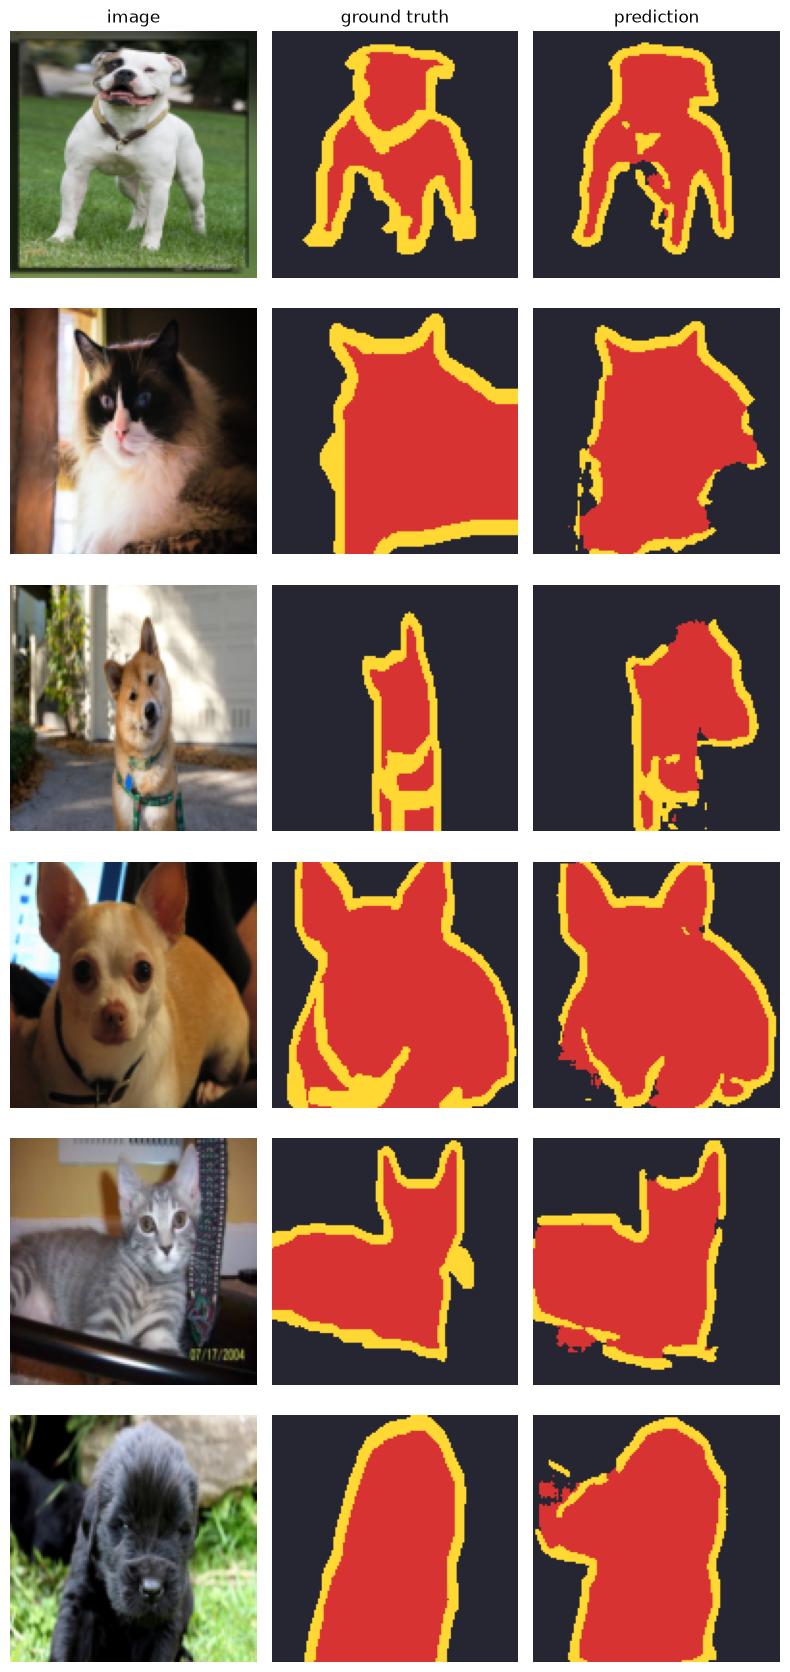

colours: red = pet, dark = background, yellow = border


In [42]:
MASK_COLORS = np.array([[0.85, 0.2, 0.2], [0.15, 0.15, 0.2], [1.0, 0.85, 0.2]])      # pet, background, border


def denormalize(x):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1); std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


show_ids = np.random.RandomState(SEED).choice(len(seg_test), 6, replace=False)
fig, axes = plt.subplots(6, 3, figsize=(8, 17))
seg_model.eval()
for row, i in enumerate(show_ids):
    x, m = seg_test[i]
    with torch.no_grad():
        p = seg_model(x[None].to(device)).argmax(1)[0].cpu()
    axes[row, 0].imshow(denormalize(x)); axes[row, 1].imshow(MASK_COLORS[m.numpy()]); axes[row, 2].imshow(MASK_COLORS[p.numpy()])
    for ax in axes[row]: ax.axis("off")
for ax, title in zip(axes[0], ["image", "ground truth", "prediction"]):
    ax.set_title(title)
plt.tight_layout(); plt.show()
print("colours: red = pet, dark = background, yellow = border")

In [43]:
set_seed()
noskip_model = UNet(use_skips=False).to(device)
noskip_hist = train_seg(noskip_model, SEG_EPOCHS)                 # identical settings
noskip_scores = evaluate_seg(noskip_model, seg_test_loader)
params_with = sum(p.numel() for p in seg_model.parameters())
params_without = sum(p.numel() for p in noskip_model.parameters())

ablation = pd.DataFrame({"with skips": seg_scores, "without skips": noskip_scores}).round(3)
ablation["difference"] = (ablation["with skips"] - ablation["without skips"]).round(3)
print(ablation)
print("\nparameters: with skips %d | without skips %d (the second network is smaller, because the decoder blocks receive fewer channels)" % (params_with, params_without))

epoch  1 | train loss 0.6625 | 21 s


epoch  2 | train loss 0.4888 | 21 s


epoch  3 | train loss 0.4262 | 20 s


epoch  4 | train loss 0.3929 | 20 s


epoch  5 | train loss 0.3589 | 21 s


epoch  6 | train loss 0.3401 | 20 s


... (3 outputs left out)

epoch 10 | train loss 0.2792 | 20 s


epoch 11 | train loss 0.2686 | 21 s


epoch 12 | train loss 0.2543 | 21 s


                with skips  without skips  difference
pet_iou              0.778          0.767       0.011
background_iou       0.874          0.861       0.013
border_iou           0.444          0.418       0.026
mean_dice            0.808          0.794       0.014

parameters: with skips 1928483 | without skips 1734947 (the second network is smaller, because the decoder blocks receive fewer channels)


### Вывод 4.3

**Цифры.** С skip-связями pet IoU = **0,778**, без них **0,767** (разница 1,1 п.п.); по фону 0,874 против 0,861 (1,3 п.п.); по границе (класс 2) **0,444 против 0,418** (2,6 п.п.). Mean Dice 0,808 против 0,794. Ориентир pet IoU ≥ 0,65 пройден с запасом.

**Что дают skip-связи.** Энкодер на разрешении 128×128 хранит точное положение краёв, а после трёх пулингов в bottleneck (16×16) эти детали теряются. Склейка возвращает их декодеру. Поэтому выигрыш по тонкой границе (2,6 п.п.) вдвое больше, чем по крупному питомцу (1,1 п.п.), как я и ожидал. На предсказанных масках видно, что у сети со skip-связями контур ушей (кошка и чихуахуа) и линия вокруг тела получаются чёткими, при этом внутри тела бывают дырки (грудь и морда бульдога): сеть путает светлую шерсть с фоном. Мелкие детали (хвост у кошки на 5-й картинке, лапы) воспроизводятся хуже всего даже со skip-связями.

**Ограничения.** Это один запуск с одним зерном. Сеть без skip-связей меньше (1,73 против 1,93 млн параметров), и разница в 1–3 п.п. сравнима с разбросом между зёрнами, который я не измерял. Поэтому вывод осторожный: skip-связи помогают, особенно на границе, но величина эффекта по одному запуску ненадёжна.

---
# Часть 5. Что видит сеть? Grad-CAM и анализ ошибок

## 5.1 Grad-CAM

**Идея.** Сеть сказала «Siamese». Какие места картинки на это повлияли? Беру **последний свёрточный блок** (`model.layer4`): он выдаёт 512 «карт признаков» маленького размера (5×5 для картинки 160×160). Для выбранного класса спрашиваю: *насколько изменится балл класса, если усилить карту `k`?* Эта чувствительность — **градиент** балла по карте. Усредняя градиент по карте, получаю **вес каждой карты `α_k`**. Складываю карты с этими весами и оставляю только положительное (`ReLU`) — получается тепловая карта 5×5 «что подтолкнуло класс вверх». Растягиваю до размера картинки и накладываю на фото.

```
α_k = (1/Z) · Σ_i Σ_j  ∂y^c / ∂A^k_ij                   (среднее градиента по карте k)
L_Grad-CAM = ReLU( Σ_k α_k · A^k )                       (взвешенная сумма карт, только положительное)
```

**Как устроена моя функция `grad_cam(model, x, class_idx=None)`** (`x` — одна картинка `(1, 3, H, W)`):
1. На `model.layer4` вешаю **два хука**: `register_forward_hook` (сохраняет выход блока — активации `A`) и `register_full_backward_hook` (сохраняет градиент по выходу блока).
2. Прямой проход в режиме `eval`, но **с** градиентами. Если класс не задан — беру предсказанный (`argmax`).
3. Беру **логит** выбранного класса `y^c` (до softmax) и вызываю по нему `.backward()`.
4. `α` — среднее градиента по высоте и ширине (форма `(512,)`); взвешиваю карты `A`, суммирую по каналам, применяю `ReLU`.
5. Растягиваю до размера входа (`F.interpolate`, `bilinear`) и делю на максимум, чтобы значения были в `[0, 1]` (с защитой от деления на ноль, если карта нулевая).
6. Хуки обязательно снимаю (`handle.remove()` в `finally`), иначе они остались бы на модели.
7. Возвращаю карту `(H, W)` как массив NumPy и номер класса.

In [44]:
def grad_cam(model, x, class_idx=None):
    """Grad-CAM for the last conv block (model.layer4) of a ResNet.

    x: input tensor (1, 3, H, W). Returns (cam, class_idx): cam is a numpy array (H, W) with values in [0, 1].
    Uses register_forward_hook and register_full_backward_hook (no grad-cam libraries).
    """
    store = {}

    def forward_hook(module, inputs, output):
        store["A"] = output.detach()                 # activations A^k, (1, 512, h, w)

    def backward_hook(module, grad_input, grad_output):
        store["G"] = grad_output[0].detach()         # d y^c / d A^k, (1, 512, h, w)

    h_fwd = model.layer4.register_forward_hook(forward_hook)
    h_bwd = model.layer4.register_full_backward_hook(backward_hook)
    try:
        model.eval()
        with torch.enable_grad():
            model.zero_grad(set_to_none=True)
            scores = model(x)                        # logits, (1, 37)
            if class_idx is None:
                class_idx = scores.argmax(1).item()
            scores[0, class_idx].backward()          # the score BEFORE softmax
        A, G = store["A"], store["G"]
        alpha = G.mean(dim=(2, 3), keepdim=True)     # (1, 512, 1, 1): average gradient of every map
        cam = F.relu((alpha * A).sum(dim=1, keepdim=True))        # (1, 1, h, w)
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam[0, 0]
        cam = cam / (cam.max() + 1e-8)               # to [0, 1]; the +1e-8 protects from an all-zero map
    finally:
        h_fwd.remove()                               # always remove the hooks
        h_bwd.remove()
        model.zero_grad(set_to_none=True)
    return cam.cpu().numpy(), class_idx

### Проверка, что мой Grad-CAM написан верно

Красивая картинка ещё не доказывает, что `grad_cam` верен: тепловая карта может нравиться глазу и ничего не значить. Поэтому проверяю количественно тремя способами:

1. **Форма и диапазон:** карта `(160, 160)`, значения в `[0, 1]`, результат одинаков при повторном вызове, хуки после вызова сняты.
2. **Тест «закрыть самое важное»:** на 100 тестовых картинках закрашиваю 20 % пикселей с **самым высоким** значением карты, и отдельно — 20 % **случайных**, и смотрю, насколько падает уверенность сети в своём ответе. Если карта верна, закрыть «важное» должно ударить **сильнее**, чем закрыть случайное.
3. **Положение внутри питомца:** какая доля «тепла» лежит **вне** питомца (по эталонной маске из датасета). Пригодится для таблицы ошибок (5.2).

In [45]:
def pet_mask_160(idx):
    """Pet region (trimap == 1 or 3) of test image `idx` at 160x160, as a boolean array. Used to measure where Grad-CAM looks."""
    trimap = Image.open(seg_test._segs[idx]).resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)
    return np.isin(np.array(trimap), [1, 3])


probe_x = test_ds[0][0][None].to(device)
probe_cam, probe_cls = grad_cam(ft_model, probe_x)
assert probe_cam.shape == (IMG_SIZE, IMG_SIZE) and probe_cam.min() >= 0 and probe_cam.max() <= 1 + 1e-6
probe_cam2, _ = grad_cam(ft_model, probe_x)
assert np.allclose(probe_cam, probe_cam2, atol=1e-5)
n_hooks_left = sum(len(m._forward_hooks) + len(m._backward_hooks) + len(m._backward_pre_hooks) for m in ft_model.modules())
assert n_hooks_left == 0, "hooks were not removed"
print("Grad-CAM: shape, range, repeatability and hook removal are fine")

Grad-CAM: shape, range, repeatability and hook removal are fine


In [46]:
rng_cam = np.random.RandomState(SEED)
check_ids = rng_cam.choice(len(test_ds), 100, replace=False)
drops_top, drops_random, outside_share = [], [], []
ft_model.eval()
for i in check_ids:
    x = test_ds[i][0][None].to(device)
    cam, cls = grad_cam(ft_model, x)
    with torch.no_grad():
        p0 = ft_model(x).softmax(1)[0, cls].item()
    k = int(0.2 * cam.size)
    order = np.argsort(cam.ravel())[::-1]
    for pixels, bucket in [(order[:k], drops_top), (rng_cam.choice(cam.size, k, replace=False), drops_random)]:
        mask = np.zeros(cam.size, bool); mask[pixels] = True
        mask_t = torch.from_numpy(mask.reshape(cam.shape)).to(device)
        x_occluded = x.clone(); x_occluded[:, :, mask_t] = 0.0           # 0 = the mean colour after normalisation
        with torch.no_grad():
            bucket.append(p0 - ft_model(x_occluded).softmax(1)[0, cls].item())
    pet = pet_mask_160(i)
    outside_share.append(cam[~pet].sum() / (cam.sum() + 1e-9))
cam_check = pd.Series({"mean confidence drop, top-20% CAM pixels hidden": np.mean(drops_top),
                       "mean confidence drop, random 20% pixels hidden": np.mean(drops_random),
                       "mean share of CAM outside the pet": np.mean(outside_share)})
print(cam_check.round(3))
assert np.mean(drops_top) > np.mean(drops_random)          # the map really points at what the decision depends on

mean confidence drop, top-20% CAM pixels hidden    0.697
mean confidence drop, random 20% pixels hidden     0.650
mean share of CAM outside the pet                  0.414
dtype: float64


### 8 наложений: 4 верных и 4 ошибочных предсказания

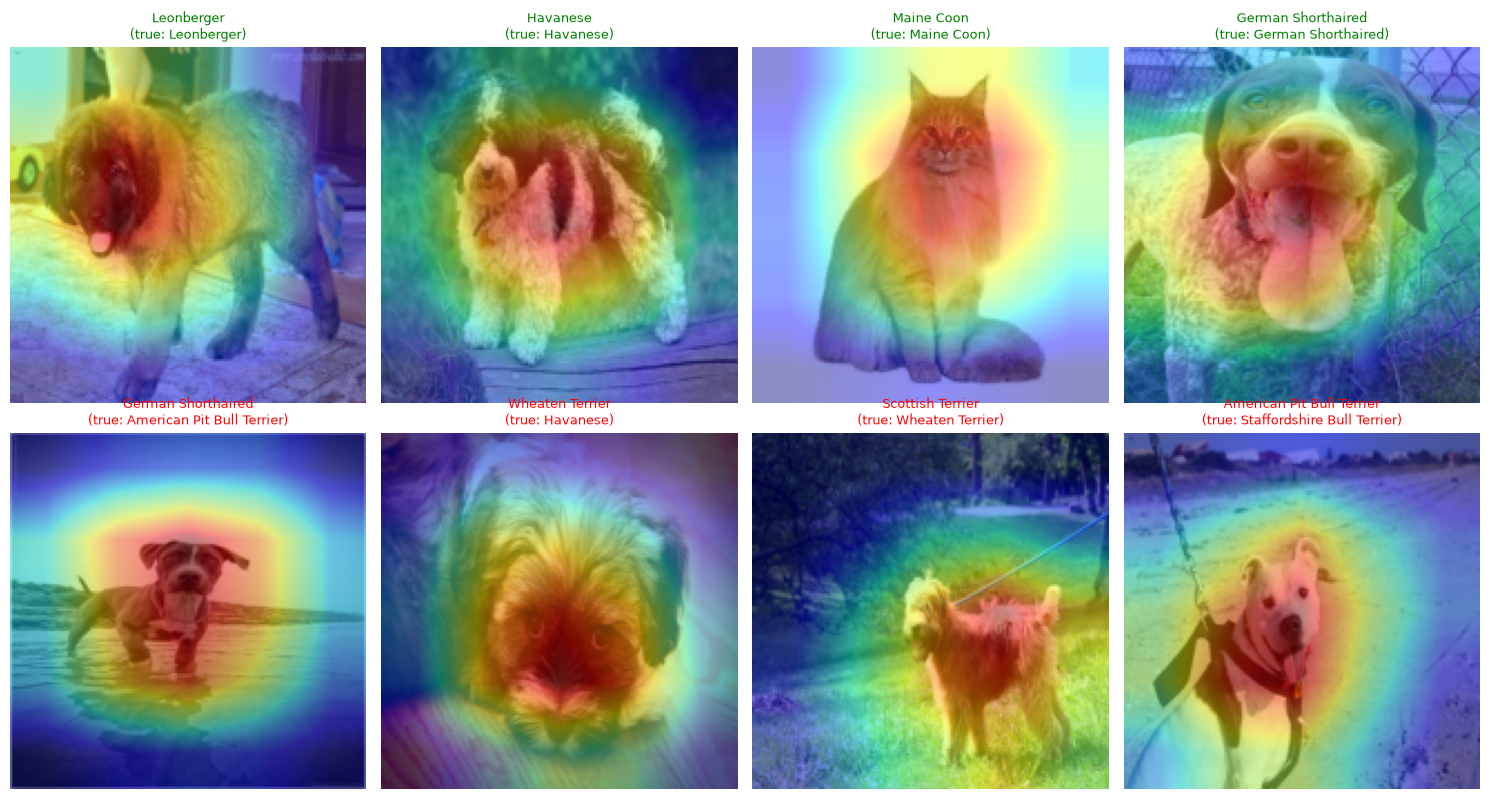

In [47]:
# predictions of the fine-tuned model on the test split (used for analysis only, never for training or tuning)
test_logits, test_y = predict_all(ft_model, test_loader)
test_prob = test_logits.softmax(1)
test_pred = test_logits.argmax(1).numpy()
test_true = test_y.numpy()
test_conf = test_prob.max(1).values.numpy()
is_wrong = test_pred != test_true

rng_show = np.random.RandomState(SEED + 1)
right_ids = rng_show.choice(np.where(~is_wrong)[0], 4, replace=False)
wrong_ids = rng_show.choice(np.where(is_wrong)[0], 4, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, i in zip(axes.ravel(), list(right_ids) + list(wrong_ids)):
    x = test_ds[i][0][None].to(device)
    cam, cls = grad_cam(ft_model, x)
    ax.imshow(denormalize(x[0])); ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.set_title("%s\n(true: %s)" % (CLASSES[cls], CLASSES[test_true[i]]), fontsize=9, color="green" if cls == test_true[i] else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

### Вывод 5.1

- **Где тепло.** На верных предсказаниях (верхний ряд) тепло лежит на морде и груди питомца (Leonberger, Maine Coon, German Shorthaired). На ошибочных (нижний ряд) оно тоже в основном на самом животном (Wheaten Terrier вместо Havanese: морда в фокусе), но карта грубая: слой `layer4` даёт всего 5×5 ячеек, поэтому «пятно» размытое и заходит на фон (немецкая овчарка вместо APBT: тепло расползлось по воде вокруг собаки).
- **Проверка «закрыть важное».** Закрытие 20 % самых «горячих» пикселей снижает уверенность в ответе в среднем на **0,697**, закрытие 20 % случайных — на **0,650**. Разница есть (`assert` пройден), но **небольшая** (0,05): карта указывает на нужное место лишь чуть лучше случайного закрытия. Причина, по моей версии (не проверял): карта 5×5 слишком грубая, а закрытые 20 % изображения при любом выборе убирают много информации.
- **Вне питомца** в среднем лежит **41 %** тепла (по эталонной маске датасета, граница считается частью питомца). Это много, но часть объясняется грубостью карты: пятно размером в одну ячейку 5×5 (32×32 пикселя) в любом случае выходит за контур.
- **Вывод.** Grad-CAM показывает, что сеть в основном смотрит на животное (морда, грудь), а не на посторонние предметы, но из-за низкого разрешения для тонкого анализа (уши, шерсть) он не годится.

## 5.2 Анализ ошибок

Модель — **дообученный ResNet-18 из 3.2**, данные — официальный **тест** (на нём мы ничего не обучали и не подбирали; тут он нужен только для анализа).

**Шаги:** (1) матрица ошибок 37×37 и топ-5 самых путаемых пар; (2) **сначала посмотреть, какие вообще причины ошибок бывают**, измерив свойства картинок, и проверить, влияют ли они на ошибки; (3) разложить 30 случайных ошибок по категориям и посчитать проценты; (4) вывод и два действия.

### Шаг 1. Матрица ошибок и самые путаемые пары

In [48]:
cm_test = confusion_matrix_np(test_true, test_pred)
top_pairs_test = top_confused_pairs(cm_test, 5)
test_acc_ft = 1 - is_wrong.mean()
errors_total = int(is_wrong.sum())
share_top5 = sum(n for _, _, n in top_pairs_test) / errors_total
same_species_test = (class_is_cat[test_true[is_wrong]] == class_is_cat[test_pred[is_wrong]]).mean()

test accuracy of the fine-tuned model: 85.4% (536 errors out of 3669 images)

top-5 most confused breed pairs (errors in both directions):
  American Pit Bull Terrier    <-> Staffordshire Bull Terrier   31
  Birman                       <-> Ragdoll                      27
  British Shorthair            <-> Russian Blue                 21
  Birman                       <-> Siamese                      17
  Basset Hound                 <-> Beagle                       16

the 5 pairs together make 21% of all errors
errors between breeds of the same species: 90%


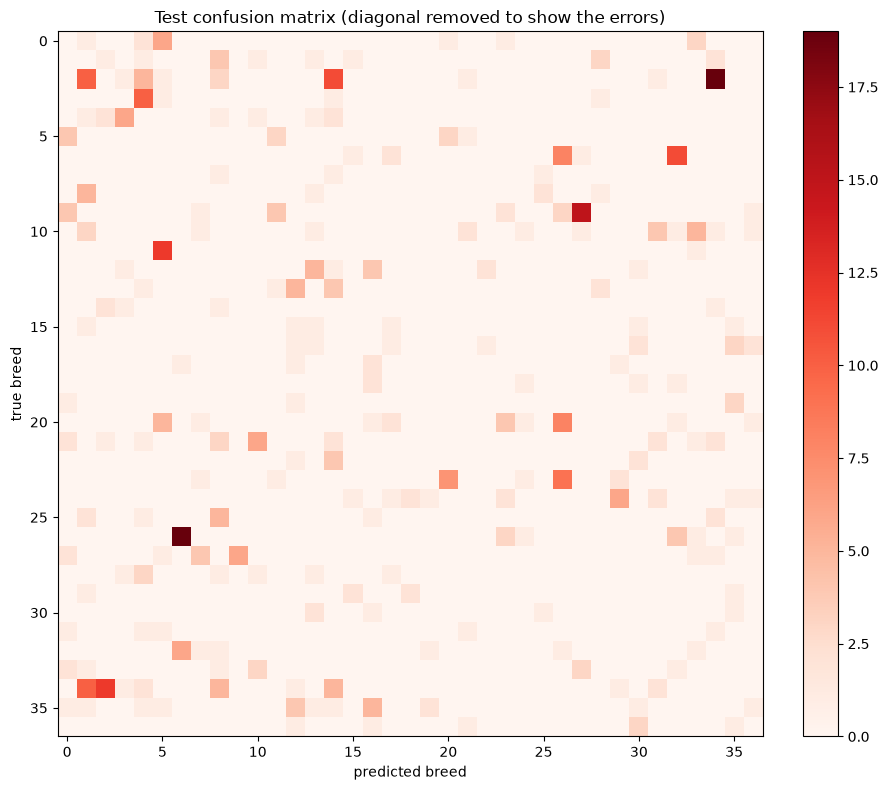

In [49]:
print("test accuracy of the fine-tuned model: %.1f%% (%d errors out of %d images)" % (100 * test_acc_ft, errors_total, len(test_true)))
print("\ntop-5 most confused breed pairs (errors in both directions):")
for a, b, n_err in top_pairs_test:
    print("  %-28s <-> %-28s %d" % (a, b, n_err))
print("\nthe 5 pairs together make %.0f%% of all errors" % (100 * share_top5))
print("errors between breeds of the same species: %.0f%%" % (100 * same_species_test))

off_diag = cm_test.copy(); np.fill_diagonal(off_diag, 0)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(off_diag, cmap="Reds")
ax.set_xlabel("predicted breed"); ax.set_ylabel("true breed"); ax.set_title("Test confusion matrix (diagonal removed to show the errors)")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

### Шаг 2. Какие свойства картинки вообще влияют на ошибки? (измеряем, а не предполагаем)

Заранее придуманные категории могут оказаться пустыми словами. Поэтому для **каждой** из 3669 тестовых картинок измеряем три свойства и сравниваем долю ошибок **внутри** группы и **вне** неё. Категория пригодна для таблицы, только если разница заметна.

| Свойство | Как измеряем |
|---|---|
| питомец маленький | доля пикселей питомца (по эталонной маске датасета) ниже 25-го процентиля |
| необычное освещение | средняя яркость ниже 10-го или выше 90-го процентиля |
| модель сомневалась | уверенность (макс. вероятность) ниже 0,5 |

In [50]:
area_fraction = np.array([np.isin(np.array(Image.open(p)), [1]).mean() for p in seg_test._segs])
brightness = np.array([np.asarray(Image.open(p).convert("L").resize((64, 64))).mean() for p in test_ds._images])

small_threshold = np.percentile(area_fraction, 25)
dark_threshold, bright_threshold = np.percentile(brightness, [10, 90])

flags = pd.DataFrame({
    "pet is small": area_fraction < small_threshold,
    "unusual lighting": (brightness < dark_threshold) | (brightness > bright_threshold),
    "model unsure (conf < 0.5)": test_conf < 0.5,
})
effect_rows = {}
for col in flags.columns:
    inside, outside = flags[col].values, ~flags[col].values
    effect_rows[col] = {"images in group": int(inside.sum()),
                        "error rate inside, %": 100 * is_wrong[inside].mean(),
                        "error rate outside, %": 100 * is_wrong[outside].mean()}
effect_table = pd.DataFrame(effect_rows).T.round(1)
effect_table["ratio"] = (effect_table["error rate inside, %"] / effect_table["error rate outside, %"]).round(2)

In [51]:
print("pet area: 25th percentile = %.1f%% of the image | brightness: 10th/90th percentile = %.0f / %.0f" % (100 * small_threshold, dark_threshold, bright_threshold))
print()
print(effect_table)

pet area: 25th percentile = 16.9% of the image | brightness: 10th/90th percentile = 77 / 155

                           images in group  error rate inside, %  error rate outside, %  ratio
pet is small                         917.0                  26.3                   10.7   2.46
unusual lighting                     734.0                  14.0                   14.8   0.95
model unsure (conf < 0.5)            349.0                  61.6                    9.7   6.35


### Потолок выигрыша: сколько ошибок можно убрать, если исправить каждую причину

По методике Andrew Ng: категория, даже исправленная идеально, уберёт не больше ошибок, чем в ней есть. Считаем два сценария: (1) маленькие питомцы ошибаются так же редко, как остальные; (2) пять самых путаемых пар исправлены полностью.

In [52]:
small_mask = flags["pet is small"].values
excess_errors_small = (is_wrong[small_mask].mean() - is_wrong[~small_mask].mean()) * small_mask.sum()
error_now = is_wrong.mean()
error_if_small_ok = (errors_total - excess_errors_small) / len(test_true)
error_if_top5_fixed = (errors_total - sum(n for _, _, n in top_pairs_test)) / len(test_true)

In [53]:
print("current test error                                : %.1f%% (%d errors)" % (100 * error_now, errors_total))
print("small pets erred %.1f%% vs %.1f%% for the rest -> %.0f 'extra' errors (%.0f%% of all errors)" % (
      100 * is_wrong[small_mask].mean(), 100 * is_wrong[~small_mask].mean(), excess_errors_small, 100 * excess_errors_small / errors_total))
print("if small pets were as easy as the rest, error would be: %.1f%%" % (100 * error_if_small_ok))
print("if the 5 most confused pairs were fixed completely     : %.1f%%" % (100 * error_if_top5_fixed))

current test error                                : 14.6% (536 errors)
small pets erred 26.3% vs 10.7% for the rest -> 143 'extra' errors (27% of all errors)
if small pets were as easy as the rest, error would be: 10.7%
if the 5 most confused pairs were fixed completely     : 11.6%


### Вывод шага 2: что влияет на ошибки, а что нет

- **Маленький питомец — реальный фактор.** Если питомец занимает меньше 16,9 % кадра, ошибка **26,3 %**, у остальных **10,7 %** (в 2,5 раза). Это категория для таблицы.
- **Необычное освещение — не причина.** Ошибка в этой группе 14,0 %, у остальных 14,8 % (отношение 0,95). Освещение на ошибки не влияет, поэтому в выводах эту категорию не используем (она остаётся в таблице как проверенная и отвергнутая гипотеза).
- **Сомнение модели — признак, а не причина.** Когда уверенность ниже 0,5, ошибок 61,6 % (в остальных случаях 9,7 %, разница в 6,4 раза): сеть «чувствует» большую часть своих ошибок. Это можно использовать: такие картинки стоит отправлять на проверку человеку.
- **Потолок выигрыша (в ячейке выше).** Если бы маленькие питомцы ошибались так же редко, как остальные, ошибка упала бы с **14,6 % до 10,7 %** (143 «лишних» ошибки, 27 % всех). Если полностью исправить пять самых путаемых пар — до **11,6 %** (минус 21 % ошибок). Два рычага сопоставимы по размеру: −3,9 п.п. и −3,0 п.п.

### Шаг 3. Таблица ошибок: 30 случайных ошибок

Для каждой ошибки отмечаем (можно несколько признаков сразу):

| Категория | Как определяем (всё измеряется кодом) |
|---|---|
| **похожие породы** | пара «настоящая — предсказанная» повторяется в тесте не менее 3 раз (в обе стороны): это систематическая путаница, а не случайный промах |
| **маленький питомец** | из шага 2 |
| **необычное освещение** | из шага 2 |
| **модель сомневалась** | из шага 2 |
| **уверенная ошибка** (замена «возможна ошибка в разметке») | уверенность ≥ 0,9: сеть не сомневалась и всё равно «ошиблась» — классический признак неверной разметки; **только подсказка**, надо смотреть глазами |
| **Grad-CAM смотрит на фон** | больше половины «тепла» вне питомца (считается моим `grad_cam`) |
| **несколько животных в кадре**, **необычная поза / питомец закрыт**, **возможная ошибка разметки** | код этого не измеряет: отмечаю **вручную** по сетке картинок под таблицей |

In [54]:
pair_errors = cm_test + cm_test.T
rng_30 = np.random.RandomState(SEED)
wrong_ids_all = np.where(is_wrong)[0]
sample_30 = np.sort(rng_30.choice(wrong_ids_all, size=min(30, len(wrong_ids_all)), replace=False))

rows = []
for i in sample_30:
    t, p = test_true[i], test_pred[i]
    row = {"image": i, "true breed": CLASSES[t], "predicted": CLASSES[p], "confidence": round(float(test_conf[i]), 2),
           "similar breeds": pair_errors[t, p] >= 3,
           "pet is small": bool(flags.loc[i, "pet is small"]),
           "unusual lighting": bool(flags.loc[i, "unusual lighting"]),
           "model unsure": bool(flags.loc[i, "model unsure (conf < 0.5)"]),
           "confident error": bool(test_conf[i] >= 0.9)}
    cam, _ = grad_cam(ft_model, test_ds[i][0][None].to(device))
    row["CAM on background"] = bool(cam[~pet_mask_160(i)].sum() / (cam.sum() + 1e-9) > 0.5)
    rows.append(row)
error_table = pd.DataFrame(rows)
error_table.index = range(1, len(error_table) + 1)

category_columns = [c for c in error_table.columns if c not in ("image", "true breed", "predicted", "confidence")]
percent_row = (100 * error_table[category_columns].mean()).round(0)
errors_in_sample = len(error_table)

    image                  true breed                   predicted  confidence similar breeds pet is small unusual lighting model unsure confident error CAM on background
1       8                  Abyssinian                      Sphynx        0.79              x                                                                            x
2      35                  Abyssinian                      Sphynx        0.27              x            x                             x                                 x
3      53                  Abyssinian                      Bengal        0.49              x                                          x                                  
4     249   American Pit Bull Terrier  Staffordshire Bull Terrier        0.50              x                                          x                                 x
5     326                Basset Hound                      Beagle        0.42              x            x                             x               

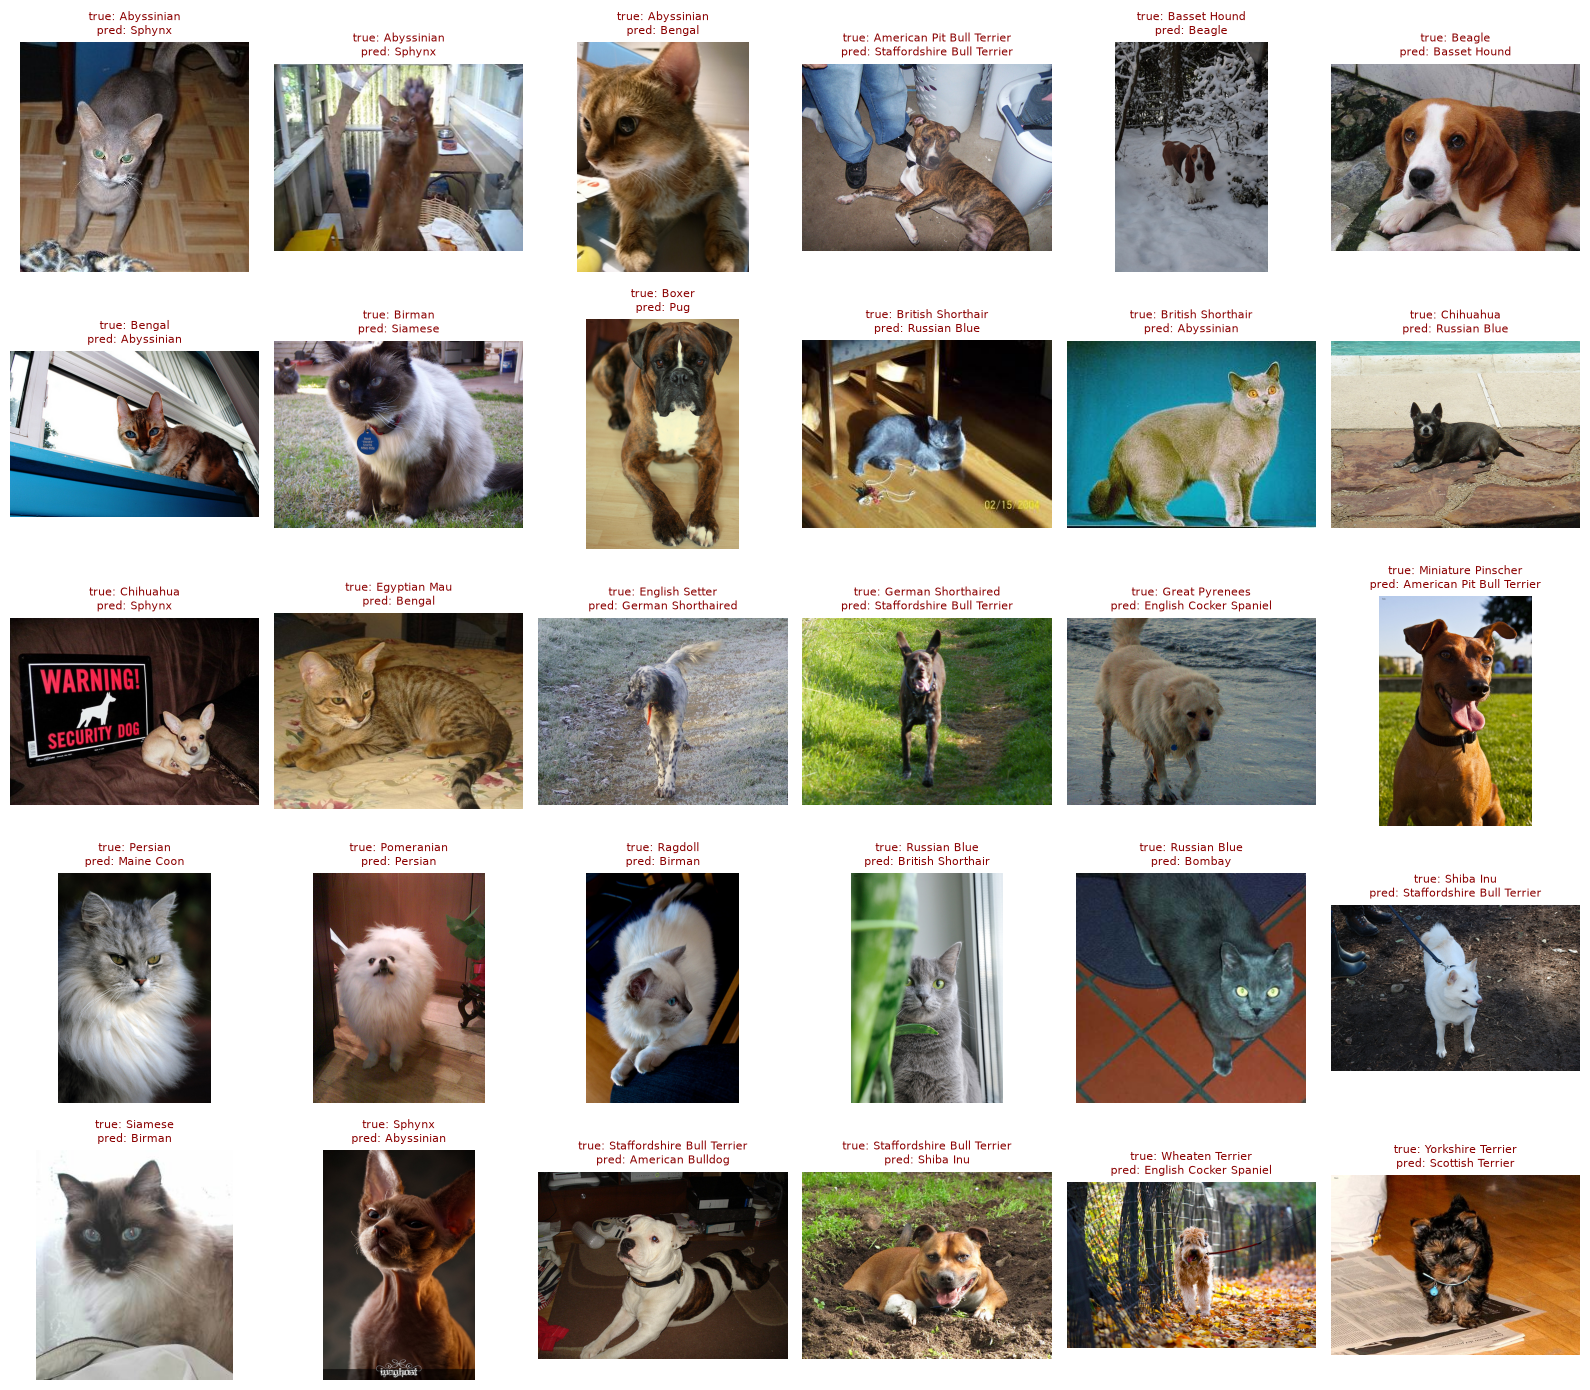

In [55]:
show_table = error_table.copy()
for c in category_columns:
    show_table[c] = show_table[c].map({True: "x", False: ""})
print(show_table.to_string())
print("\nshare of the %d errors in each category, %%:" % errors_in_sample)
print(percent_row.to_string())
print("\nnot measured by code: 'several animals in the frame' (look at the grid below)")

fig, axes = plt.subplots(5, 6, figsize=(16, 14))
for ax, i in zip(axes.ravel(), sample_30):
    ax.imshow(Image.open(test_ds._images[i]).convert("RGB"))
    ax.set_title("true: %s\npred: %s" % (CLASSES[test_true[i]], CLASSES[test_pred[i]]), fontsize=8, color="darkred"); ax.axis("off")
for ax in axes.ravel()[len(sample_30):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [56]:
# Manual labels: I looked at the grid of the 30 images above (numbers = rows of the table).
manual = {
    "several animals": [8, 9],                                       # 8: second cat in the background, 9: second dog at the left edge
    "unusual pose / occluded": [2, 4, 7, 13, 15, 21, 22, 23, 26, 29],   # pet reaches up, lies under a person, behind a window/plant/fence, seen from above...
    "possible label error": [17, 25, 27],                            # 17: Great Pyrenees looks golden; 25, 27: confident prediction and the photo fits the predicted breed
}
for name, rows_ in manual.items():
    error_table[name] = error_table.index.isin(rows_)

all_columns = [c for c in error_table.columns if c not in ("image", "true breed", "predicted", "confidence")]
final_table = error_table[["true breed", "predicted", "confidence"] + all_columns].copy()
for c in all_columns:
    final_table[c] = final_table[c].map({True: "x", False: ""})
final_table.loc["% of errors"] = [""] * 3 + ["%.0f%%" % (100 * error_table[c].mean()) for c in all_columns]
pd.set_option("display.max_colwidth", 30)
print(final_table.to_string())
print("\nthe largest bucket:", (100 * error_table[all_columns].mean()).idxmax(), "-", "%.0f%%" % (100 * error_table[all_columns].mean().max()))

                             true breed                   predicted confidence similar breeds pet is small unusual lighting model unsure confident error CAM on background several animals unusual pose / occluded possible label error
1                            Abyssinian                      Sphynx       0.79              x                                                                            x                                                             
2                            Abyssinian                      Sphynx       0.27              x            x                             x                                 x                                       x                     
3                            Abyssinian                      Bengal       0.49              x                                          x                                                                                               
4             American Pit Bull Terrier  Staffordshire Bull Terrier     

### Вывод 5.2 (анализ ошибок)

1. Дообученный ResNet-18 ошибся на **536 из 3 669** тестовых картинок (14,6 %).
2. Ошибки **системные, а не случайные**: **90 %** — путаница пород одного вида, и пять пар дают 21 % всех ошибок (American Pit Bull Terrier ↔ Staffordshire Bull Terrier — 31, Birman ↔ Ragdoll — 27, British Shorthair ↔ Russian Blue — 21, Birman ↔ Siamese — 17, Basset Hound ↔ Beagle — 16).
3. В таблице из 30 случайных ошибок **крупнейший бакет — «похожие породы»: 90 % (27 из 30)**: это повторяющаяся путаница пар, а не одиночные промахи.
4. Следом идёт «Grad-CAM смотрит на фон» (53 %), но этот признак надо читать осторожно: карта 5×5 грубая, и в среднем по 100 случайным тестовым картинкам вне питомца лежит 41 % тепла (см. 5.1). Потом «модель сомневалась» (43 %), «маленький питомец» (40 %) и «необычная поза или питомец частично закрыт» (33 %, отмечено вручную). Маленький питомец — настоящая причина (ошибка 26,3 % против 10,7 % у остальных), а сомнение модели — следствие, а не причина.
5. «Необычное освещение» (27 % в таблице) ошибки не объясняет: по всему тесту влияния нет (14,0 % против 14,8 %), 27 % — просто доля таких картинок (в тесте их 20 %).
6. Вручную по сетке картинок я отметил **3 возможные ошибки разметки** (10 %): Great Pyrenees — на фото рыжеватая собака, Siamese и Staffordshire Bull Terrier — модель уверена на 0,96 и 0,90, а на фото скорее другая порода. «Несколько животных в кадре» — **2 из 30 (7 %)**. Оценки грубые: выборка мала, разметка моя субъективная, поэтому в выводах я опираюсь на цифры по всему тесту.
7. **Действие 1 — маленькие питомцы.** Подавать сети питомца крупнее: больший вход (224 вместо 160 px) или обрезка кадра по питомцу (в части 4 U-Net как раз выделяет питомца по маске). Потолок выигрыша: **14,6 % → 10,7 %** (−3,9 п.п.).
8. **Действие 2 — самые путаемые пары.** Собрать и разметить больше примеров именно для этих пар (в первую очередь APBT ↔ Staffordshire, Birman ↔ Ragdoll, British Shorthair ↔ Russian Blue), а заодно перепроверить подозрительные ярлыки у уверенных ошибок. Ещё стоит проверить, не мешает ли `ColorJitter` в обучении (у части пар порода различается цветом шерсти; это гипотеза, я её не проверял). Потолок выигрыша: **14,6 % → 11,6 %** (−3,0 п.п.).

---
# Бонус. Эффективность данных

**Вопрос:** когда transfer learning нужнее всего? Повторяем бейзлайн (часть 2) и feature extraction (3.1) на **10 %, 25 %, 50 % и 100 %** обучающей части (те же эпохи: 15 и 5, те же зёрна, одна и та же валидационная выборка). Результаты для 100 % берём из частей 2 и 3.1: это те же запуски.

In [57]:
FRACTIONS = [0.10, 0.25, 0.50, 1.00]
bonus = {"baseline": {}, "feature_extraction": {}}
bonus_images = {}
for frac in FRACTIONS:
    n_used = int(frac * len(train_idx))
    bonus_images[frac] = n_used
    if frac == 1.0:
        bonus["baseline"][frac] = baseline_hist["val_acc"][-1]
        bonus["feature_extraction"][frac] = fe_hist["val_acc"][-1]
        continue
    sub_loader = DataLoader(TransformSubset(full_trainval, train_idx[:n_used], train_tf), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    set_seed()
    model_b = SimpleCNN().to(device)
    h = fit(model_b, torch.optim.AdamW(model_b.parameters(), lr=1e-3, weight_decay=1e-4), epochs=15, loader=sub_loader, log=False)
    bonus["baseline"][frac] = h["val_acc"][-1]
    set_seed()
    model_f = make_resnet()
    for p_ in model_f.parameters(): p_.requires_grad = False
    for p_ in model_f.fc.parameters(): p_.requires_grad = True
    h = fit(model_f, torch.optim.AdamW([p_ for p_ in model_f.parameters() if p_.requires_grad], lr=1e-3), epochs=5, freeze_bn=True, loader=sub_loader, log=False)
    bonus["feature_extraction"][frac] = h["val_acc"][-1]
    print("fraction %.2f done (%d images)" % (frac, n_used))

bonus_table = pd.DataFrame(bonus, index=FRACTIONS) * 100
bonus_table.insert(0, "training images", [bonus_images[f] for f in FRACTIONS])
bonus_table["gap (pp)"] = bonus_table["feature_extraction"] - bonus_table["baseline"]
bonus_table["images per breed"] = (bonus_table["training images"] / len(CLASSES)).round(1)

fraction 0.10 done (294 images)


fraction 0.25 done (736 images)


fraction 0.50 done (1472 images)


      training images  baseline  feature_extraction  gap (pp)  images per breed
0.10              294       7.9                53.4      45.5               7.9
0.25              736       7.9                75.3      67.4              19.9
0.50             1472      16.8                81.2      64.4              39.8
1.00             2944      19.2                83.8      64.7              79.6


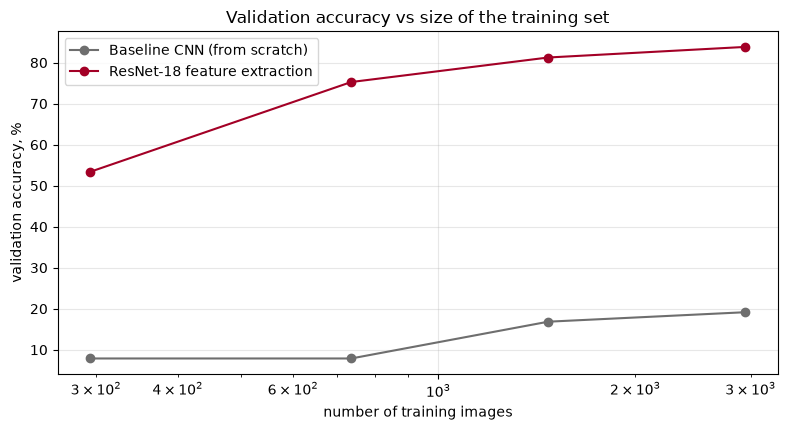

In [58]:
print(bonus_table.round(1))
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(bonus_table["training images"], bonus_table["baseline"], marker="o", color="#6E6E6E", label="Baseline CNN (from scratch)")
ax.plot(bonus_table["training images"], bonus_table["feature_extraction"], marker="o", color=BRAND, label="ResNet-18 feature extraction")
ax.set_xlabel("number of training images"); ax.set_ylabel("validation accuracy, %"); ax.set_xscale("log")
ax.set_title("Validation accuracy vs size of the training set"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

### Вывод бонуса

- **Цифры.** Feature extraction: 53,4 % (294 картинки, примерно 8 на породу) → 75,3 % → 81,2 % → **83,8 %** (2 944 картинки). Бейзлайн: 7,9 % → 7,9 % → 16,8 % → **19,2 %**.
- **Преимущество предобучения огромно при любом размере данных:** разрыв составляет 45,5 п.п. при 10 % данных и 64–67 п.п. при 25–100 %. При самых малых данных предобученная голова уже в 20 раз лучше случайного угадывания (53,4 % против 2,7 %), а бейзлайн лишь в 3 раза (7,9 %).
- **Кривые устроены по-разному.** Feature extraction быстро выходит на плато (от 25 % до 100 % данных +8,5 п.п.), а бейзлайн растёт медленно и остаётся далеко от неё: ему данных нужно гораздо больше. Поэтому transfer learning нужнее всего, когда данных мало; в нашем диапазоне разрыв не сокращается (он сократится только при заметно большем наборе, чего мы не проверяли).
- **Оговорки.** Число эпох фиксировано (15 и 5), поэтому при 10–25 % данных шагов оптимизации в 4–10 раз меньше. Для бейзлайна это существенно (в 2.3 мы показали, что и 15 эпох ему мало), так что его кривая занижена. Погрешность каждой точки около ±1,5 п.п. (736 картинок в валидации), а запуск один.